In [1]:
from common import *

from MDAnalysis.analysis.align import alignto

In [2]:
compute = True

### Forward mapping

By bound RNA site:

In [3]:
device = 'cuda'
chunk_size = 8192

methods = ['replex', 'plain_md']
systems = ['7ez0', '7ez0_noion']
forcefields = ['mMg_tip3p', 'nMg_tip3p', 'nMg_tip3p_soft']
replicates = [0, 1]
repids = range(8)
alignment = 'local'

def run(method, sys, ff, rep, repid, alignment):

    path = PROJECT_DIR / f'{method}/{sys}/{ff}/replicate{rep}/rep{repid+rep*8:02d}'
    if not path.exists():
        return

    outpath = PROJECT_DIR / f'density/{method}_{sys}_{ff}/{alignment}/site'
    outpath.mkdir(exist_ok=True, parents=True)

    ref_hmap_A, ref_hmap_B = Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_A.mrc"), Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_B.mrc")
    ref_map = 0.5 * (ref_hmap_A + ref_hmap_B)
    grid_params = ref_map.grid_params

    ref = mda.Universe(PROJECT_DIR / "structures/9CBU_fixed.pdb")
    ref.atoms[ref.atoms.names == 'OP1'].names = 'O1P'
    ref.atoms[ref.atoms.names == 'OP2'].names = 'O2P'
    ref_rna = ref.select_atoms("nucleic and not type H and not (resid 22 and name P O1P O2P)")

    u = mda.Universe(
        path / f'input.gro',
        path / f'run.xtc',
    )
    u.add_TopologyAttr('tempfactors', np.full(shape=len(u.atoms), fill_value=30.0))
    rna = u.select_atoms("nucleic and not type H and not (resid 22 and name P O1P O2P)")
    mob_out = u.select_atoms('not type H')

    traj_frames = np.arange(len(u.trajectory))
    if method == 'plain_md':
        traj_frames = traj_frames[traj_frames % 24 == 0]
    traj_times = traj_frames * int(u.trajectory.dt)
    if method == 'replex':
        colvar = read_plumed(path / f'bias.COLVAR.{repid}')
        colvar['time'] = colvar['time'].astype(int)
        reptemp = colvar.set_index('time').loc[traj_times, 'bias.index']
    else:
        reptemp = np.zeros_like(traj_frames)
    all_frames = traj_frames[reptemp == 0]

    if alignment == 'global':
        ref_align_ag = reorder_residue_atoms(ref_rna)
        mob_align_ag = reorder_residue_atoms(rna)
        check_alignable(mob_align_ag, ref_align_ag)

    site_selection = []
    for a_site in ref_rna.select_atoms('name O1P O2P'):
        site = f'{a_site.resname}{a_site.resid}{a_site.name}'
        ref_ag = mda.AtomGroup([a_site])
        mob_ag = rna.select_atoms(f"name {a_site.name} and resid {a_site.resid} and resname {a_site.resname}")
        out_ag = mob_out.select_atoms(
            "group mob_ag or (around 10 group mob_ag)",
            mob_ag=mob_ag,
            updating=True,
        )
        bound_mg_ag = out_ag.select_atoms(
            "name MG and around 2.8 group mob_ag",
            mob_ag=mob_ag,
            updating=True,
        )
        # Grid mask
        vox_indices = voxels_around(ref_ag, 6, grid_params)

        # Prepare selections for alignment of ref and mobile
        if alignment == 'local':
            # Local neighborhood
            ref_align_ag = ref_rna.select_atoms("(around 10 group ref_ag) or group ref_ag", ref_ag=ref_ag)
            mob_align_ag = rna.select_atoms(*[
                    f"name {a.name} and resid {a.resid} and resname {a.resname}"
                    for a in ref_align_ag
                ])
            check_alignable(mob_align_ag, ref_align_ag)

        map_present = SparseGrid(
            data=np.zeros_like(vox_indices),
            vox_indices=vox_indices,
            **grid_params,
        )
        map_absent = SparseGrid(
            data=np.zeros_like(vox_indices),
            vox_indices=vox_indices,
            **grid_params,
        )
        site_selection.append(dict(
            site=site,
            ref_ag=ref_ag,
            mob_ag=mob_ag,
            out_ag=out_ag,
            bound_mg_ag=bound_mg_ag,
            ref_align_ag=ref_align_ag,
            mob_align_ag=mob_align_ag,
            vox_indices=vox_indices,
            frames_present=[],
            frames_absent=[],
            map_present=map_present,
            map_absent=map_absent,
        ))

    site_selection = pd.DataFrame(site_selection)

    for ts in tqdm(u.trajectory[all_frames]):
        # Make RNA whole
        unwrap_sequential(rna)

        # Combining multiple wrap + align messes up relative positions,
        # we have to restore the initial frame
        pos = mob_out.positions.copy()
        for i in site_selection.index:
            # Wrap solvent around motifs
            wrap_around(site_selection.loc[i, 'out_ag'], site_selection.loc[i, 'mob_ag'].center_of_mass())
            # Alignment
            alignto(site_selection.loc[i, 'mob_align_ag'], site_selection.loc[i, 'ref_align_ag'], subselection=site_selection.loc[i, 'out_ag'])
            # Get map
            map_ = atomgroup_to_map(
                site_selection.loc[i, 'out_ag'],
                shape=grid_params['shape'],
                delta=grid_params['delta'],
                origin=grid_params['origin'],
                vox_indices=site_selection.loc[i, 'vox_indices'],
                cutoff=4.0,
                device=device,
                chunk_size=chunk_size,
            )
            # Add it to the total
            if len(site_selection.loc[i, 'bound_mg_ag']) > 0:
                site_selection.loc[i, 'map_present'] += map_
                site_selection.loc[i, 'frames_present'].append(ts.frame)
            else:
                site_selection.loc[i, 'map_absent'] += map_
                site_selection.loc[i, 'frames_absent'].append(ts.frame)
            # Restore coordinates
            mob_out.positions = pos
    
    site_selection['map_present'] = site_selection['map_present'] / site_selection['frames_present'].map(lambda x: max(len(x), 1))
    site_selection['map_absent'] = site_selection['map_absent'] / site_selection['frames_absent'].map(lambda x: max(len(x), 1))

    df = site_selection[['site', 'frames_present', 'frames_absent', 'map_present', 'map_absent']]
    df.to_pickle(outpath / f'replicate{rep}_repid{repid:02d}.pkl')
    return df

In [8]:
if compute:
    from dask.distributed import Client
    from dask import delayed, compute

    n_workers = 6
    tasks = []
    for args in itertools.product(methods, systems, forcefields, replicates, repids, ['local']):
        tasks.append(
            delayed(run)(*args)
        )

    with Client(threads_per_worker=1, n_workers=n_workers) as client:
        print(f"Computing {len(tasks)} tasks…", flush=True)
        print("Dashboard:", client.dashboard_link)
        compute(*tasks)

Computing 192 tasks…
Dashboard: http://127.0.0.1:8787/status


/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/sit

KeyboardInterrupt: 

### Evaluation

In [19]:
df = []
for method, sys, ff, rep, repid, alignment in itertools.product(methods, systems, forcefields, replicates, repids, ['local']):
    outpath = PROJECT_DIR / f'density/{method}_{sys}_{ff}/{alignment}/individual/replicate{rep}_repid{repid:02d}.pkl'
    if not outpath.exists():
        continue
    df.append(pd.read_pickle(outpath).assign(sim=f'{method}_{sys}_{ff}', method=method, system=sys, forcefield=ff, replicate=rep, repid=repid, alignment=alignment))
df = pd.concat(df)
df.head()

,motif,frames_present,frames_absent,map_present,map_absent,sim,method,system,forcefield,replicate,repid,alignment
0,A103O1P-Oph,"[719, 856, 862, 865, 874, 875, 881, 891, 892, ...","[0, 92, 100, 140, 148, 153, 156, 158, 160, 166...",<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,0,0,local
1,A103O2P-Oph,"[92, 100, 140, 148, 153, 156, 158, 160, 166, 1...","[0, 439, 476, 533, 540, 549, 584, 606, 643, 71...",<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,0,0,local
2,A104O1P-Oph,[],"[0, 92, 100, 140, 148, 153, 156, 158, 160, 166...",<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,0,0,local
3,A104O2P-Oph,"[140, 148, 153, 156, 158, 160, 166, 168, 171, ...","[0, 92, 100, 172, 174, 178, 179, 181, 190, 191...",<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,0,0,local
4,A105O1P-Oph,[],"[0, 92, 100, 140, 148, 153, 156, 158, 160, 166...",<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,0,0,local


In [20]:
f_range = np.linspace(0, 1, 11)
ref_hmap_A, ref_hmap_B = Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_A.mrc"), Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_B.mrc")

def get_cc(df, n_bootstrap=200):
    n_blocks = len(df)
    n_present = df['frames_present'].map(len).to_numpy()  # (n_blocks,)
    n_absent = df['frames_absent'].map(len).to_numpy()  # (n_blocks,)
    maps_present = np.stack(df['map_present'].map(lambda x: x.data).to_numpy())  # (n_blocks, n_vox)
    maps_absent = np.stack(df['map_absent'].map(lambda x: x.data).to_numpy())  # (n_blocks, n_vox)
    vox_indices = df['map_present'].iloc[0].vox_indices  # (n_vox, )
    ref_maps_sub = np.stack([ref_hmap_A.to_sparse(vox_indices=vox_indices).data, ref_hmap_B.to_sparse(vox_indices=vox_indices).data])  # (2, n_vox)

    map_present = np.average(maps_present, weights=n_present, axis=0)  # (n_vox,)
    map_absent = np.average(maps_absent, weights=n_absent, axis=0)  # (n_vox,)
    ref_map_sub = np.average(ref_maps_sub, axis=0)  # (n_vox,)
    cc = linregress(
        f_range[:, None] * map_present + (1 - f_range)[:, None] * map_absent,
        ref_map_sub,
        axis=-1,
    ).rvalue  # (n_frac,)
    best_f = f_range[np.argmax(cc)]

    # Error estimation with bayesian bootstrap

    w_block_bs = np.random.dirichlet(np.ones(n_blocks), n_bootstrap)  # (n_bootstrap, n_blocks)
    w_ref_bs = np.random.dirichlet(np.ones(2), n_bootstrap)  # (n_bootstrap, 2)
    map_present_bs = (maps_present * w_block_bs[:, :, None] * n_present[:, None]).sum(axis=1) / (w_block_bs * n_present).sum(axis=1, keepdims=True)  # (n_bootstrap, n_vox)
    map_absent_bs = (maps_absent * w_block_bs[:, :, None] * n_absent[:, None]).sum(axis=1) / (w_block_bs * n_absent).sum(axis=1, keepdims=True)  # (n_bootstrap, n_vox)
    ref_map_sub_bs = (ref_maps_sub * w_ref_bs[:, :, None]).sum(axis=1) / w_ref_bs.sum(axis=1, keepdims=True)  # (n_bootstrap, n_vox)
    cc_bs = linregress(
        f_range[:, None, None] * map_present_bs + (1 - f_range)[:, None, None] * map_absent_bs,
        ref_map_sub_bs,
        axis=-1,
    ).rvalue  # (n_frac, n_bootstrap)
    cc_mean = np.mean(cc_bs, axis=-1)  # (n_frac,)
    cc_low, cc_high = np.quantile(cc_bs, (0.025, 0.975), axis=-1)
    best_f_bs = f_range[np.argmax(cc_bs, axis=0)]  # (n_bootstrap,)
    best_f_mean = np.mean(best_f_bs)
    best_f_low, best_f_high = np.quantile(best_f_bs, (0.025, 0.975))

    return pd.Series({
        'map_present': map_present,
        'map_absent': map_absent,
        'cc': cc,
        'cc_mean': cc_mean,
        'cc_low': cc_low,
        'cc_high': cc_high,
        'best_f': best_f,
        'best_f_mean': best_f_mean,
        'best_f_low': best_f_low,
        'best_f_high': best_f_high,
    })

if compute:
    result = df.groupby(['motif', 'sim', 'alignment']).apply(get_cc)
    result.to_pickle('individual_motif.pkl')
else:
    result = pd.read_pickle('individual_motif.pkl')

In [21]:
result.head()

map_present  \
motif       sim                           alignment                                                      
A103O1P-Oph plain_md_7ez0_nMg_tip3p       local      [0.16164996676500246, 0.10932221789590094, 0.0...   
            plain_md_7ez0_noion_nMg_tip3p local      [0.15005970901363033, 0.10392657112859854, 0.0...   
            replex_7ez0_mMg_tip3p         local      [0.17278036383997186, 0.11670698865341156, 0.0...   
            replex_7ez0_noion_mMg_tip3p   local      [0.1577243138215403, 0.10634597213918409, 0.08...   
A103O2P-Oph plain_md_7ez0_nMg_tip3p_soft  local      [0.31231488584982176, 0.2427097118071291, 0.19...   

                                                                                            map_absent  \
motif       sim                           alignment                                                      
A103O1P-Oph plain_md_7ez0_nMg_tip3p       local      [0.1637096474418904, 0.11025126786591025, 0.08...   
            plain_md_7ez0_noion_nMg_tip3p local      [0.14492658534055855, 0.10143282027507136, 0.0...   
            replex_7ez0_mMg_tip3p         local      [0.16295411571472276, 0.1094439987302317, 0.08...   
            replex_7ez0_noion_mMg_tip3p   local      [0.1546207470226945, 0.1060465357304588, 0.086...   
A103O2P-Oph plain_md_7ez0_nMg_tip3p_soft  local      [0.2722170557912116, 0.2817593875687824, 0.168...   

                                                                                                    cc  \
motif       sim                           alignment                                                      
A103O1P-Oph plain_md_7ez0_nMg_tip3p       local      [0.8649099028521854, 0.8655325920507654, 0.865...   
            plain_md_7ez0_noion_nMg_tip3p local      [0.8737762092104158, 0.8742634048797994, 0.874...   
            replex_7ez0_mMg_tip3p         local      [0.8606204370000661, 0.8637801028825645, 0.866...   
            replex_7ez0_noion_mMg_tip3p   local      [0.8720414814207392, 0.8724963477713225, 0.872...   
A103O2P-Oph plain_md_7ez0_nMg_tip3p_soft  local      [0.826094711213864, 0.8207556075426579, 0.8141...   

                                                                                               cc_mean  \
motif       sim                           alignment                                                      
A103O1P-Oph plain_md_7ez0_nMg_tip3p       local      [0.8619644909716909, 0.8627399267410175, 0.862...   
            plain_md_7ez0_noion_nMg_tip3p local      [0.8703051789264985, 0.8709555043819469, 0.870...   
            replex_7ez0_mMg_tip3p         local      [0.8576740501134956, 0.8606202453803925, 0.862...   
            replex_7ez0_noion_mMg_tip3p   local      [0.8699128985324456, 0.8703631337656116, 0.870...   
A103O2P-Oph plain_md_7ez0_nMg_tip3p_soft  local      [0.8199664452510577, 0.8144996309971116, 0.807...   

                                                                                                cc_low  \
motif       sim                           alignment                                                      
A103O1P-Oph plain_md_7ez0_nMg_tip3p       local      [0.8508424497298189, 0.8521910973997471, 0.852...   
            plain_md_7ez0_noion_nMg_tip3p local      [0.8571162096737676, 0.8592496973283568, 0.859...   
            replex_7ez0_mMg_tip3p         local      [0.848103310826135, 0.8505386753943203, 0.8515...   
            replex_7ez0_noion_mMg_tip3p   local      [0.8567102430235963, 0.8579045118144649, 0.858...   
A103O2P-Oph plain_md_7ez0_nMg_tip3p_soft  local      [0.7880381459933272, 0.7837783018801355, 0.771...   

                                                                                               cc_high  \
motif       sim                           alignment                                                      
A103O1P-Oph plain_md_7ez0_nMg_tip3p       local      [0.8700642347164049, 0.8698859468733355, 0.869...   
            plain_md_7ez0_noion_nMg_tip3p local      [0.88

In [22]:
def atom_latex_name(s):
    return f"\mathrm{{{s[0]}}}_\mathrm{{{s[1:]}}}"

def motif_latex_name(x):
    names = x['inner_names']
    resnames = x['inner_resnames']
    resids = x['inner_resids']
    mgrna = x['mgrna']
    motif = ",".join(f"${atom_latex_name(name)}^\mathrm{{{resname}{resid}}}$" for resname, resid, name in zip(resnames, resids, names))
    if x['stereo']:
        motif = x['stereo'] + "-" + motif
    return motif
# Collect all motifs summaries

res = pd.DataFrame()

# Replex
systems = ['7ez0', '7ez0_noion']
for sys in systems:
    _res = pd.read_parquet(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/MG_motifs_summary_lambda0.parquet').assign(sim=f'replex_{sys}_mMg_tip3p', method='replex', system=sys, forcefield='mMg_tip3p')
    res = pd.concat([res, _res])

# PlainMD
systems = ['7ez0', '7ez0_noion']
forcefields = ['mMg_tip3p', 'nMg_tip3p', 'nMg_tip3p_soft']
for sys, ff in itertools.product(systems, forcefields):
    try:
        _res = pd.read_parquet(PROJECT_DIR / f'plain_md/{sys}/{ff}/replicate0/MG_motifs_summary.parquet').assign(sim=f'plain_md_{sys}_{ff}', method='plain_md', system=sys, forcefield=ff)
    except FileNotFoundError:
        pass
    else:
        res = pd.concat([res, _res])

# References
_res = pd.read_parquet(PROJECT_DIR / f'structures/7ez0/mMg_tip3p/MG_motifs_summary.parquet').assign(sim=f'7ez0_pdb', method='pdb', system='7ez0', forcefield='')
res = pd.concat([res, _res])
_res = pd.read_parquet(PROJECT_DIR / f'structures/7ez0/mMg_tip3p/MG_motifs_equil_summary.parquet').assign(sim=f'7ez0_equil', method='equil', system='7ez0', forcefield='mMg_tip3p')
res = pd.concat([res, _res])
_res = pd.read_parquet(PROJECT_DIR / f'structures/9cbu/MG_motifs_summary.parquet').assign(sim=f'9cbu', method='pdb', system='9cbu', forcefield='')
res = pd.concat([res, _res])
res = res.drop(index="").reset_index()
# res = res.query('n_inner > 1')
res['inner_labels'] = res.apply(lambda x: [f"{resname}{resid}{name}" for resname, resid, name in zip(x['inner_resnames'], x['inner_resids'], x['inner_names'])], axis=1)
# res['motif_group'] = label_disjoint_sets(res['inner_labels'])
# res['group_max_p'] = res.groupby('motif_group')['p'].transform('max')
res['motif_max_p'] = res.groupby('motif')['p'].transform('max')
res = res.query('motif_max_p > 0.01')
motif_latex = res.set_index('motif').apply(motif_latex_name, axis=1).drop_duplicates()
# p = res.set_index(['group_max_p', 'motif_group', 'motif_max_p', 'motif', 'sim'])['p']

In [23]:
res.head()

,motif,p,p_low,p_high,n_block_obs,n_inner,inner_indices,inner_names,inner_resids,inner_resnames,stereo,mgrna,mg_indices,sim,method,system,forcefield,inner_labels,motif_max_p
0,A103O1P-Oph,0.19125,1.169821e-01,0.334182,15,1,[2606],[O1P],[103],[A],,Oph,"[269824, 269826, 269838, 269842, 269845, 12451...",replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,[A103O1P],0.199500
1,A103O2P-Oph,0.23550,1.060075e-01,0.386751,10,1,[2607],[O2P],[103],[A],,Oph,"[269856, 269826, 269798, 269832, 269833, 26983...",replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,[A103O2P],0.321107
2,A104O1P-Oph,0.10850,2.522315e-02,0.259908,3,1,[2639],[O1P],[104],[A],,Oph,"[269827, 269860, 269845]",replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,[A104O1P],0.179786
3,"A104O2P,U267O2P-cis-2Oph",0.00025,1.707429e-53,0.003022,1,2,"[2640, 7885]","[O2P, O2P]","[104, 267]","[A, U]",cis,cis-2Oph,[269879],replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,"[A104O2P, U267O2P]",0.015964
4,A104O2P-Oph,0.25125,1.387662e-01,0.432299,13,1,[2640],[O2P],[104],[A],,Oph,"[269857, 269821, 269859, 269891, 269796, 26983...",replex_7ez0_mMg_tip3p,replex,7ez0,mMg_tip3p,[A104O2P],0.337429


Merge simulation and cryo-EM estimations

In [31]:
df = pd.merge(
    res.set_index(['motif', 'sim']),
    result,
    on=['motif', 'sim'],
).sort_index()

In [32]:
df.head()

p     p_low    p_high  \
motif       sim                                                           
A103O1P-Oph plain_md_7ez0_nMg_tip3p        0.054679  0.019094  0.097276   
            plain_md_7ez0_noion_nMg_tip3p  0.052821  0.006484  0.137835   
            replex_7ez0_mMg_tip3p          0.191250  0.116982  0.334182   
            replex_7ez0_noion_mMg_tip3p    0.199500  0.131581  0.267971   
A103O2P-Oph plain_md_7ez0_nMg_tip3p_soft   0.321107  0.126369  0.602965   

                                           n_block_obs  n_inner inner_indices  \
motif       sim                                                                 
A103O1P-Oph plain_md_7ez0_nMg_tip3p                  4        1        [2606]   
            plain_md_7ez0_noion_nMg_tip3p            3        1        [2606]   
            replex_7ez0_mMg_tip3p                   15        1        [2606]   
            replex_7ez0_noion_mMg_tip3p             15        1        [2606]   
A103O2P-Oph plain_md_7ez0_nMg_tip3p_soft             4        1        [2607]   

                                          inner_names inner_resids  \
motif       sim                                                      
A103O1P-Oph plain_md_7ez0_nMg_tip3p             [O1P]        [103]   
            plain_md_7ez0_noion_nMg_tip3p       [O1P]        [103]   
            replex_7ez0_mMg_tip3p               [O1P]        [103]   
            replex_7ez0_noion_mMg_tip3p         [O1P]        [103]   
A103O2P-Oph plain_md_7ez0_nMg_tip3p_soft        [O2P]        [103]   

                                          inner_resnames stereo  ...  \
motif       sim                                                  ...   
A103O1P-Oph plain_md_7ez0_nMg_tip3p                  [A]         ...   
            plain_md_7ez0_noion_nMg_tip3p            [A]         ...   
            replex_7ez0_mMg_tip3p                    [A]         ...   
            replex_7ez0_noion_mMg_tip3p              [A]         ...   
A103O2P-Oph plain_md_7ez0_nMg_tip3p_soft             [A]         ...   

                                                                                 map_present  \
motif       sim                                                                                
A103O1P-Oph plain_md_7ez0_nMg_tip3p        [0.16164996676500246, 0.10932221789590094, 0.0...   
            plain_md_7ez0_noion_nMg_tip3p  [0.15005970901363033, 0.10392657112859854, 0.0...   
            replex_7ez0_mMg_tip3p          [0.17278036383997186, 0.11670698865341156, 0.0...   
            replex_7ez0_noion_mMg_tip3p    [0.1577243138215403, 0.10634597213918409, 0.08...   
A103O2P-Oph plain_md_7ez0_nMg_tip3p_soft   [0.31231488584982176, 0.2427097118071291, 0.19...   

                                                                                  map_absent  \
motif       sim                                                                                
A103O1P-Oph plain_md_7ez0_nMg_tip3p        [0.1637096474418904, 0.11025126786591025, 0.08...   
            plain_md_7ez0_noion_nMg_tip3p  [0.14492658534055855, 0.10143282027507136, 0.0...   
            replex_7ez0_mMg_tip3p          [0.16295411571472276, 0.1094439987302317, 0.08...   
            replex_7ez0_noion_mMg_tip3p    [0.1546207470226945, 0.1060465357304588, 0.086...   
A103O2P-Oph plain_md_7ez0_nMg_tip3p_soft   [0.2722170557912116, 0.2817593875687824, 0.168...   

                                                                                          cc  \
motif       sim                                                                                
A103O1P-Oph plain_md_7ez0_nMg_tip3p        [0.8649099028521854, 0.8655325920507654, 0.865...   
            plain_md_7ez0_noion_nMg_tip3p  [0.8737762092104158, 0.8742634048797994, 0.874...   
            replex_7ez0_mMg_tip3p          [0.8606204370000661, 0.8637801028825645, 0.866...   
            replex_7ez0_noion_mMg_tip3p    [0.8720414814207392, 0.8724963477713225, 0.872...   
A103O2P-Oph plain_md_7ez0_nMg_tip3p_so

In [114]:
df['inner_indices'].agg(np.concatenate)

/tmp/ipykernel_3780/3609032359.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  df['inner_indices'].agg(np.concatenate)


array([2606, 2606, 2606, ..., 2055, 2056, 2056], shape=(2105,))

In [75]:
x = pd.DataFrame(
    {
    'n_within_error': ((df['p_low'] <= df['best_f_high']) & (df['p_high'] >= df['best_f_low'])).groupby('sim').sum(),
    'n_above': (df['p_low'] > df['best_f_high']).groupby('sim').sum(),
    'n_below': (df['p_high'] < df['best_f_low']).groupby('sim').sum(),
    'total': df.groupby('sim').size(),
    }
)
for col in ['within_error', 'above', 'below']:
    x[f'p_{col}'] = x[f'n_{col}'] / x['total']
x

,n_within_error,n_above,n_below,total,p_within_error,p_above,p_below
sim,,,,,,,
plain_md_7ez0_mMg_tip3p,16,5,3,24,0.666667,0.208333,0.125000
plain_md_7ez0_nMg_tip3p,143,85,36,264,0.541667,0.321970,0.136364
plain_md_7ez0_nMg_tip3p_soft,182,53,26,261,0.697318,0.203065,0.099617
plain_md_7ez0_noion_nMg_tip3p,140,74,29,243,0.576132,0.304527,0.119342
replex_7ez0_mMg_tip3p,277,215,92,584,0.474315,0.368151,0.157534
replex_7ez0_noion_mMg_tip3p,287,221,96,604,0.475166,0.365894,0.158940


/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


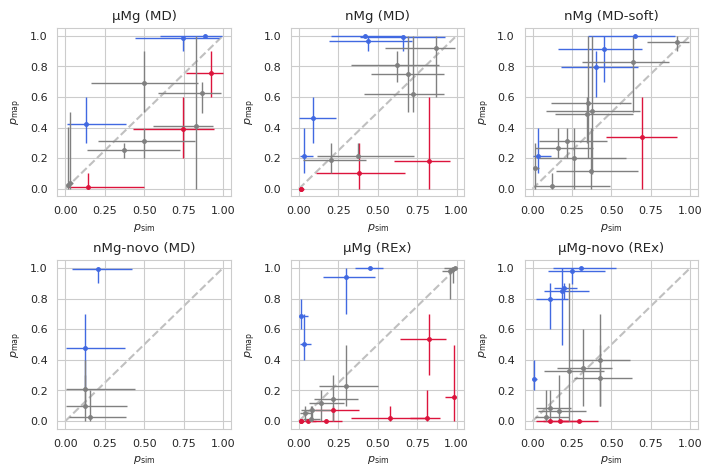

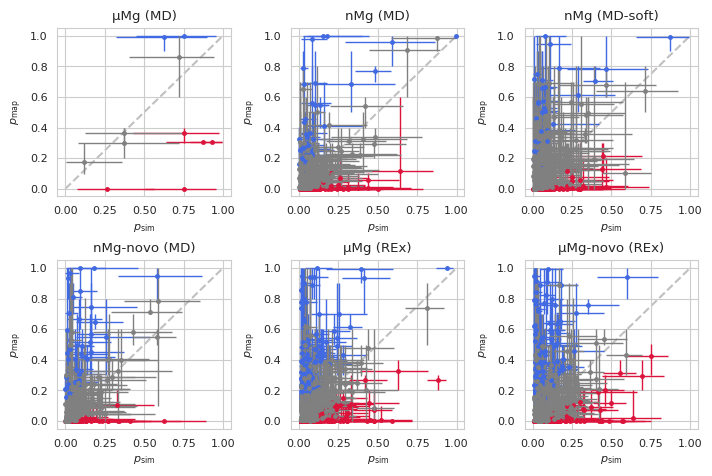

In [100]:
for motiftype, motifsel in {'multidentate': 'n_inner > 1', 'monodentate': 'n_inner == 1'}.items():
    fig, axarr = plt.subplots(ncols=3, nrows=2, figsize=(17.8*cm,11.8*cm))

    for ((sim,), group), ax in zip(df.query(motifsel).groupby(['sim']), axarr.flat):

        colors = ['crimson', 'royalblue', 'gray']
        conditions = [
            'p_low > best_f_mean & p > best_f_high',
            'p_high < best_f_mean & p < best_f_low',
            'not (p_low > best_f_mean & p > best_f_high) & not (p_high < best_f_mean & p < best_f_low)',

        ]
        for color, condition in zip(colors, conditions):
            x = group.query(condition)
            xerr = (x['p'] - x['p_low']).clip(0, None), (x['p_high'] - x['p']).clip(0, None)
            yerr =  (x['best_f_mean'] - x['best_f_low']).clip(0, None), (x['best_f_high'] - x['best_f_mean']).clip(0, None)
            ax.errorbar(
                x['p'], 
                x['best_f_mean'],
                xerr=xerr,
                yerr=yerr,
                c=color,
                fmt='.',
                elinewidth=1,
                markersize=5,
                ecolor=color,
            )
        ax.plot([0, 1], [0, 1], color='silver', ls='dashed', zorder=-10)
        ax.set_title(simlabels[sim])
        ax.set_xlabel(r'$p_\mathrm{sim}$')
        ax.set_ylabel(r'$p_\mathrm{map}$')
    fig.savefig(f'{motiftype}_psim_pmap.pdf')

In [86]:
def plot_map_slice(
    grid: Grid,
    func: str = "imshow",
    plane="xy",
    depth=0.5,
    depth_mode="fraction",
    thickness=0,
    ax=None,
    **kwargs,
):
    if ax is None:
        ax = plt.gca()

    if isinstance(func, str):
        func = getattr(ax, func)

    x_axis, y_axis = ["xyz".index(dim) for dim in plane]
    depth_axis = ({0, 1, 2} - set((x_axis, y_axis))).pop()
    midpoints = grid.midpoints[depth_axis]
    dx = grid.delta[depth_axis]
    x_edges, y_edges = grid.edges[x_axis], grid.edges[y_axis]
    extent = [*x_edges[[0, -1]], *y_edges[[0, -1]]]
    z_edges = grid.edges[depth_axis]

    if depth_mode == "fraction":
        k = int(depth * len(midpoints))
        dk = int(thickness * len(midpoints))
    elif depth_mode == "index":
        k = int(depth)
        dk = int(thickness)
    elif depth_mode == "coord":
        k = int(np.searchsorted(midpoints, depth, side="left"))
        dk = int(np.searchsorted(midpoints - midpoints[0], thickness, side="left"))

    if thickness == 0:
        s = tuple(slice(None) if d in (x_axis, y_axis) else k for d in (0, 1, 2))
        img = grid.grid[s].T
    else:
        k_min = max(k-dk, 0)
        k_max = min(k+dk, len(midpoints))
        s = tuple(slice(None) if d in (x_axis, y_axis) else slice(k_min, k_max) for d in (0, 1, 2))
        img = grid.grid[s].mean(axis=depth_axis).T

    out = func(img, origin="lower", extent=extent, **kwargs)

    ax.set_xlabel("xyz"[x_axis])
    ax.set_ylabel("xyz"[y_axis])

    return out

In [87]:
results

,motif,alignment,cc_mean,cc_low,cc_high,best_frac_mean,best_frac_low,best_frac_high,map_present,map_absent,map_ref
0,"A172O2P,A173O2P-cis-2Oph",local,"[0.752831293976669, 0.7622592803013427, 0.7709...","[0.743195320047923, 0.7538845022165133, 0.7641...","[0.7636053011260093, 0.7713825881496607, 0.778...",1.0000,1.0000,1.0000,<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...
1,"A207O1P,C262O2P-cis-2Oph",local,"[0.7270889717777387, 0.7348486479738201, 0.741...","[0.6831076010717335, 0.6954341551552445, 0.706...","[0.747440116229929, 0.7539072549861953, 0.7591...",0.6300,0.3975,1.0000,<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...
2,"A256O1P,U273O1P-cis-2Oph",local,"[0.7583479761488515, 0.7754612308202351, 0.790...","[0.7523161941447727, 0.770322246548279, 0.7862...","[0.7682699292142338, 0.7829879847991101, 0.797...",0.9675,0.7975,1.0000,<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...
3,"A301O1P,A302O2P-cis-2Oph",local,"[0.6826248619403082, 0.7077879408132695, 0.730...","[0.6269954122002493, 0.6602968125254561, 0.693...","[0.743218693131839, 0.7552105231437836, 0.7677...",0.7825,0.7000,0.9000,<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...
4,"A304O1P,A306O1P-cis-2Oph",local,"[0.7183619268109233, 0.7354642532456671, 0.750...","[0.707202270695278, 0.7246807498384111, 0.7406...","[0.7258914102238052, 0.7423527024479645, 0.758...",0.7675,0.7000,0.8000,<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...
5,"A369O2P,A370O2P-cis-2Oph",local,"[0.5703680625983074, 0.5689239711234778, 0.566...","[0.5593551026048873, 0.5579574481969017, 0.556...","[0.5789078438047172, 0.5775548445313814, 0.575...",0.0075,0.0000,0.1025,<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...
6,"C166O1P,U168O1P-cis-2Oph",local,"[0.7554833021522799, 0.7595626693032413, 0.762...","[0.7235190763421243, 0.7332168148958617, 0.741...","[0.7748379555174875, 0.7762839042920879, 0.776...",0.4075,0.2000,0.7000,<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...
7,"C166O2P,U168O1P-cis-2Oph",local,"[0.7277203383452504, 0.7326508897397526, 0.736...","[0.7228756512590854, 0.7284859183269925, 0.732...","[0.7340247017568274, 0.7378689524940931, 0.740...",0.3725,0.3000,0.4000,<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...
8,"C208O1P,A304O1P,A306O1P-fac-3Oph",local,"[0.7773181446040012, 0.7826589984769342, 0.785...","[0.7678191290735236, 0.7734747261721396, 0.775...","[0.7861790208293906, 0.7907500514387096, 0.793...",0.2750,0.2000,0.3000,<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...
9,"G257O1P,U258O2P,C260O2,U305O2P-Cis-3OphOb",local,"[0.7976627952267507, 0.8006619290948468, 0.802...","[0.7669728512942906, 0.7713696183460929, 0.774...","[0.8176936964627891, 0.8180666695932056, 0.818...",0.2700,0.0975,0.5000,<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...,<mg_sampling.density.grid.SparseGrid object at...


In [94]:
df = []
for method, sys, ff in [
    ('replex', '7ez0', 'mMg_tip3p'),
    ('replex', '7ez0_noion', 'mMg_tip3p'),
    ('plain_md', '7ez0', 'nMg_tip3p'),
    ('plain_md', '7ez0_noion', 'nMg_tip3p'),
]:
    outpath = PROJECT_DIR / f'density/{method}_{sys}_{ff}/{alignment}/individual'
    df.append(pd.read_pickle(outpath / "results.pkl").assign(method=method, sys=sys, ff=ff))
results = pd.concat(df)

In [96]:
motifs_summary

,p,p_low,p_high,n_block_obs,n_inner,inner_indices,inner_names,inner_resids,inner_resnames,stereo,mgrna,mg_indices,sys,method
motif,,,,,,,,,,,,,,
,112.46450,1.111919e+02,113.862082,16,0,[],[],[],[],,,"[269824, 269825, 269826, 269827, 269828, 26982...",7ez0,replex
A103O1P-Oph,0.19125,1.169821e-01,0.334182,15,1,[2606],[O1P],[103],[A],,Oph,"[269824, 269826, 269838, 269842, 269845, 12451...",7ez0,replex
A103O2P-Oph,0.23550,1.060075e-01,0.386751,10,1,[2607],[O2P],[103],[A],,Oph,"[269856, 269826, 269798, 269832, 269833, 26983...",7ez0,replex
A104O1P-Oph,0.10850,2.522315e-02,0.259908,3,1,[2639],[O1P],[104],[A],,Oph,"[269827, 269860, 269845]",7ez0,replex
"A104O2P,U267O2P-cis-2Oph",0.00025,1.707429e-53,0.003022,1,2,"[2640, 7885]","[O2P, O2P]","[104, 267]","[A, U]",cis,cis-2Oph,[269879],7ez0,replex
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"G257O1P,U258O2P,C260O2,U305O2P-Cis-3OphOb",1.00000,1.000000e+00,1.000000,8,4,"[7564, 7599, 7680, 9103]","[O1P, O2P, O2, O2P]","[257, 258, 260, 305]","[G, U, C, U]",Cis,Cis-3OphOb,[12456],7ez0_PDB,NaN
U258O1P-Oph,1.00000,1.000000e+00,1.000000,8,1,[7598],[O1P],[258],[U],,Oph,[12457],7ez0_PDB,NaN
U259O1P-Oph,1.00000,1.000000e+00,1.000000,8,1,[7628],[O1P],[259],[U],,Oph,[12458],7ez0_PDB,NaN


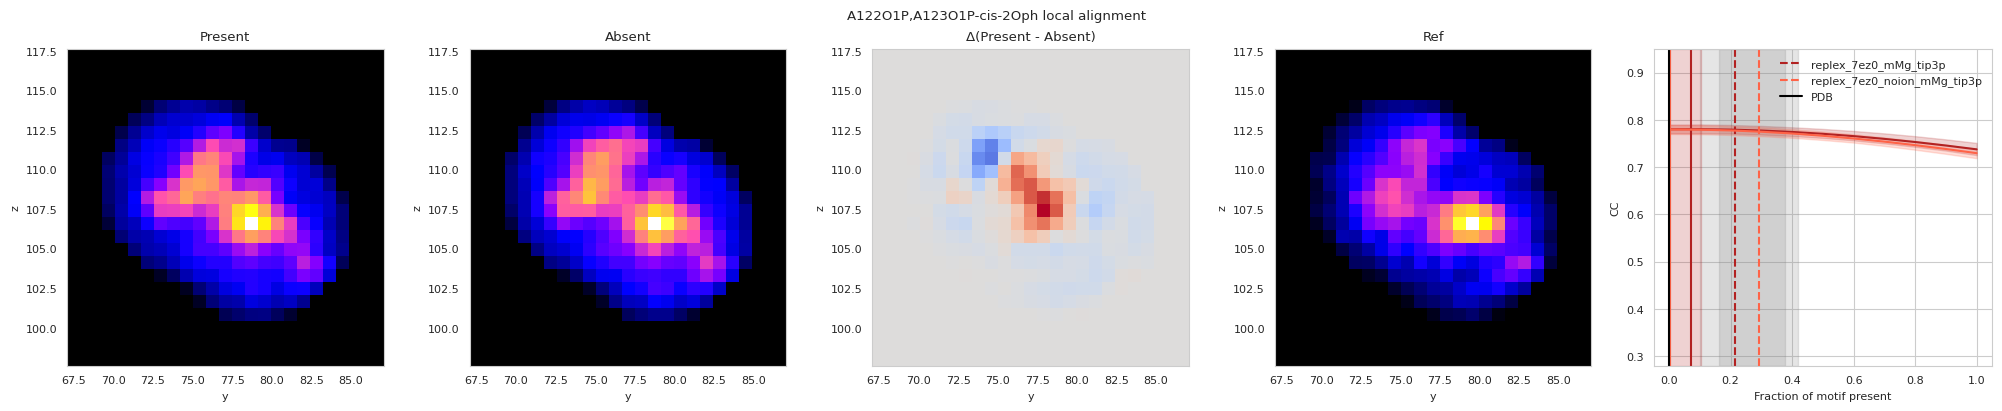

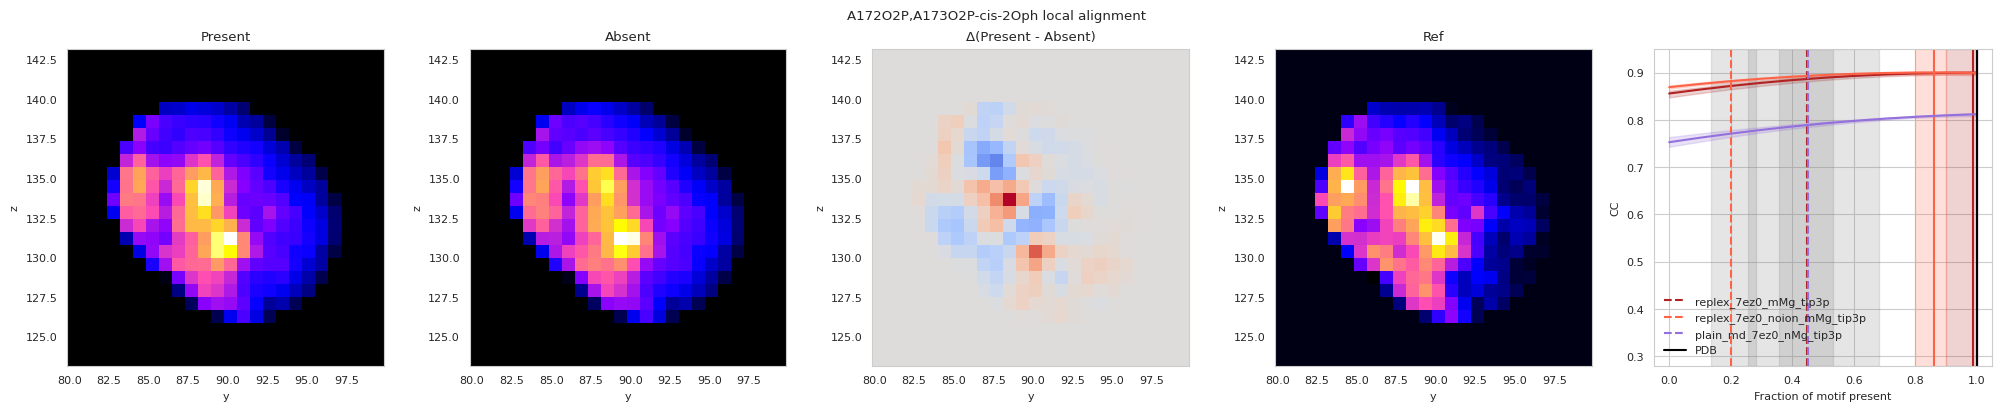

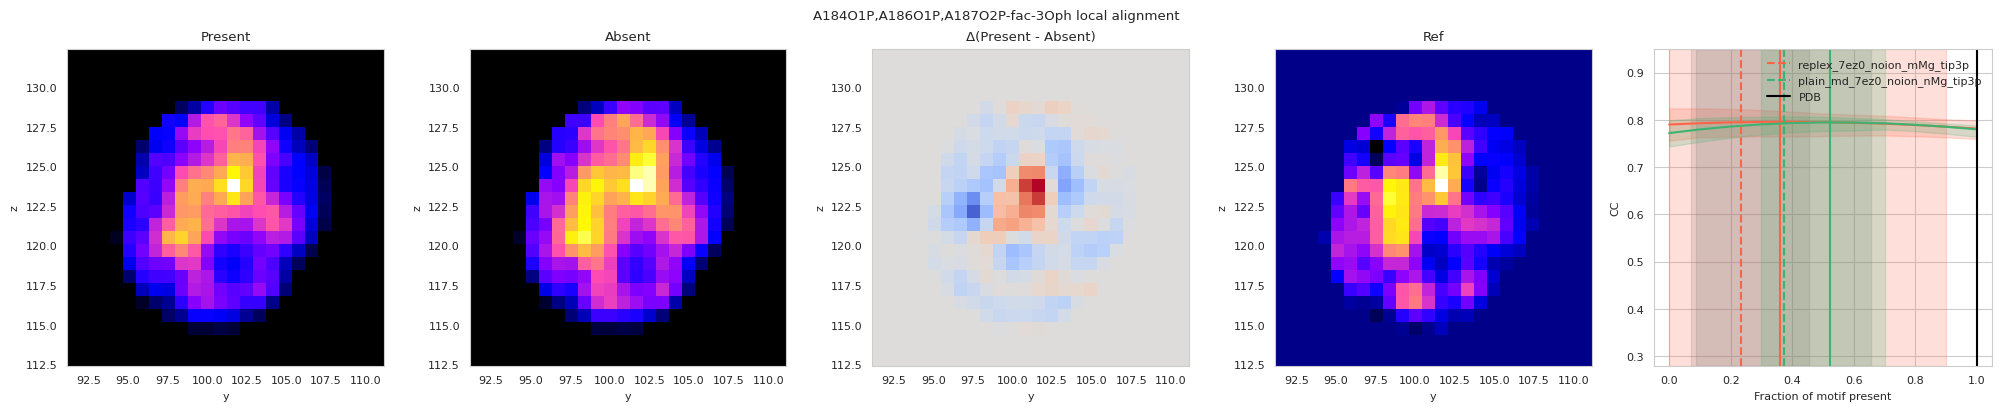

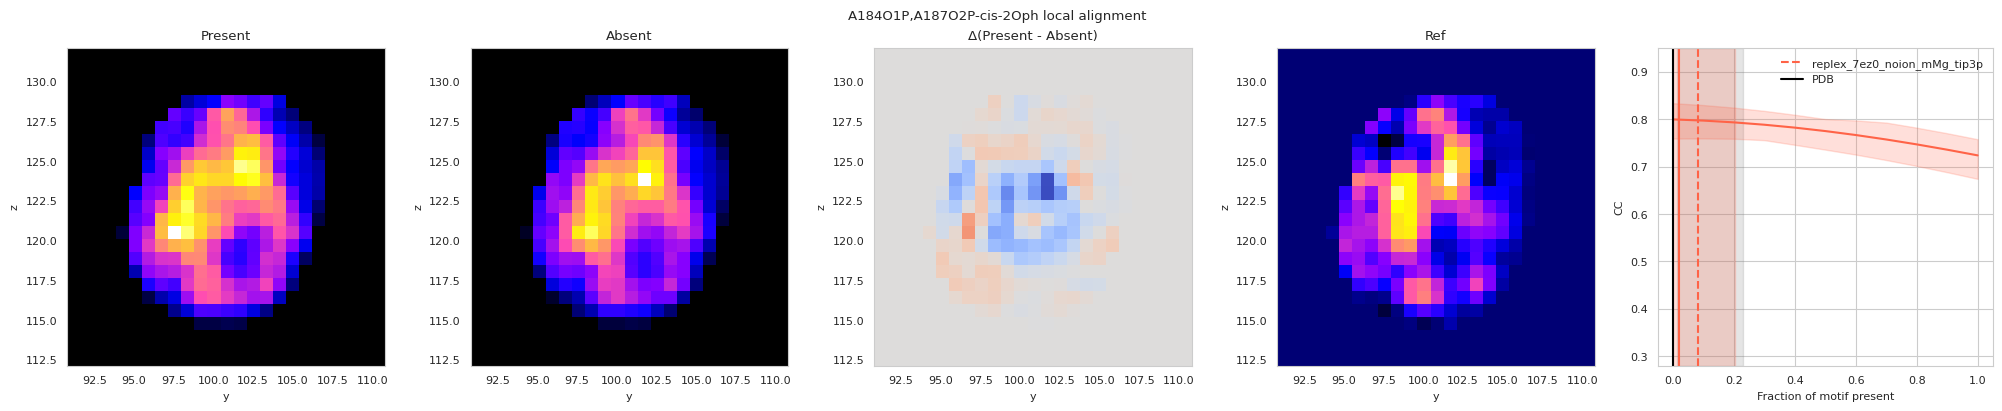

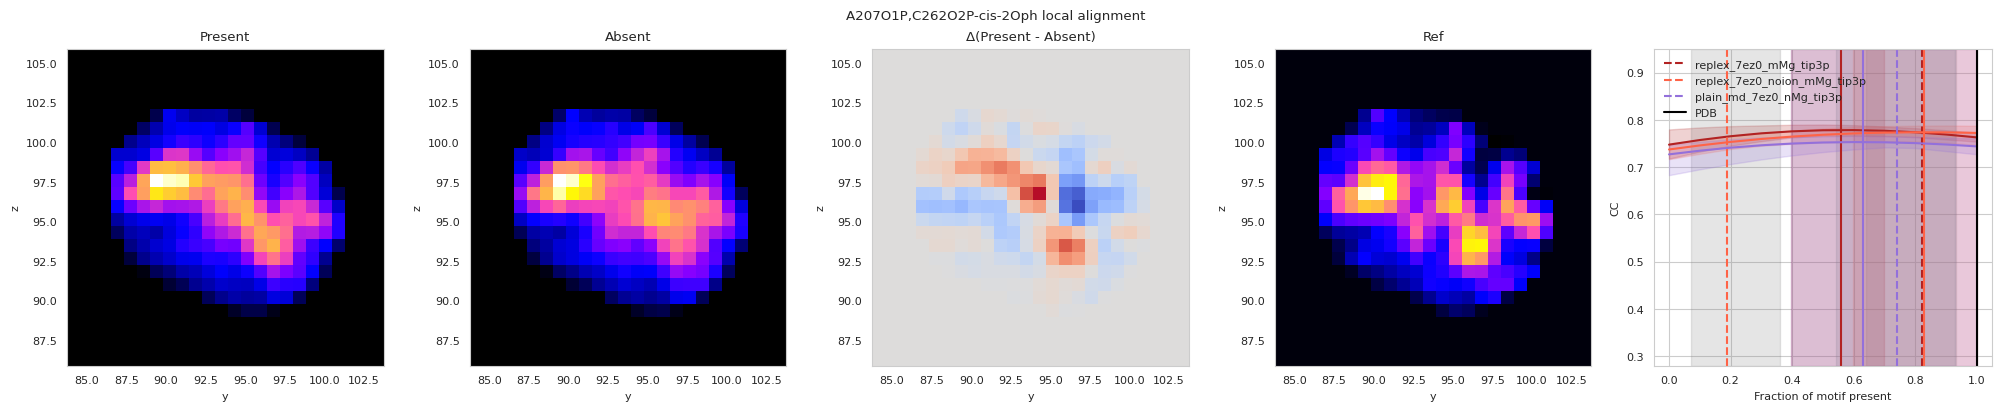

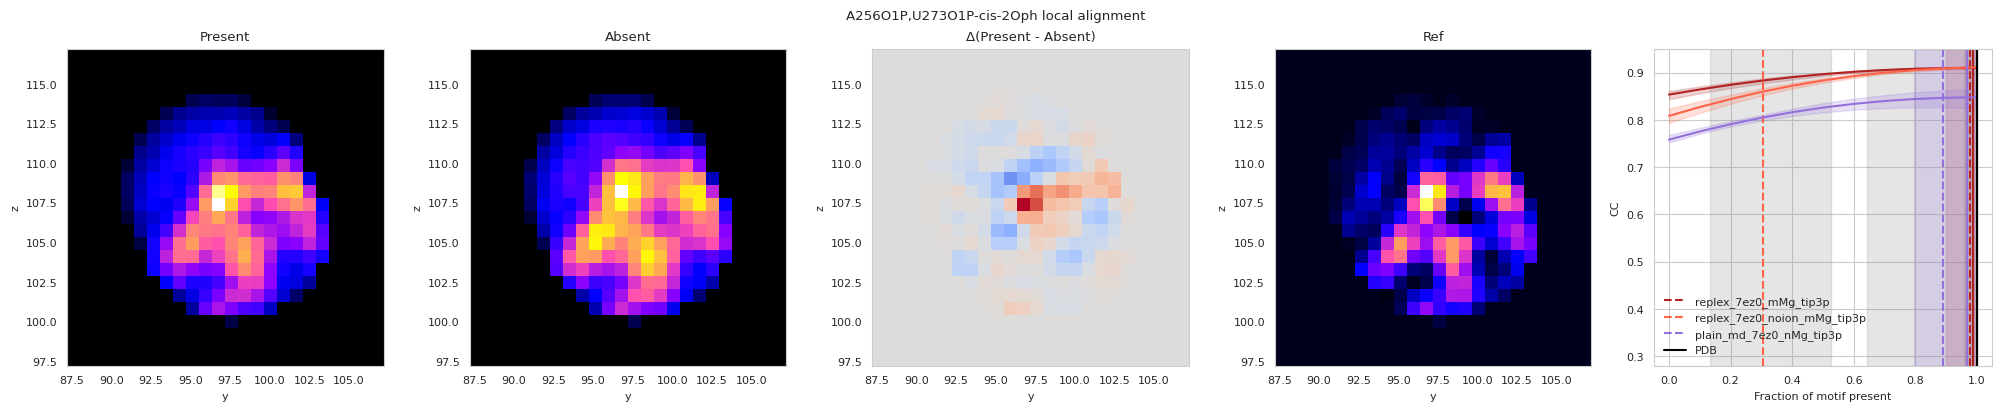

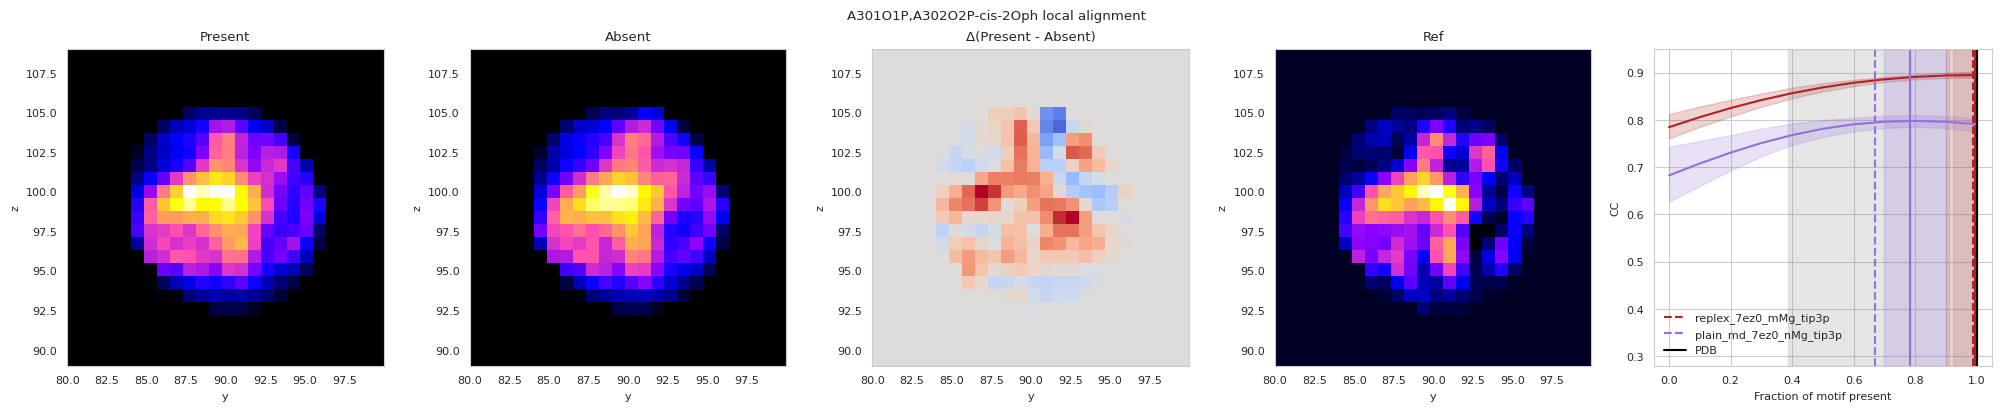

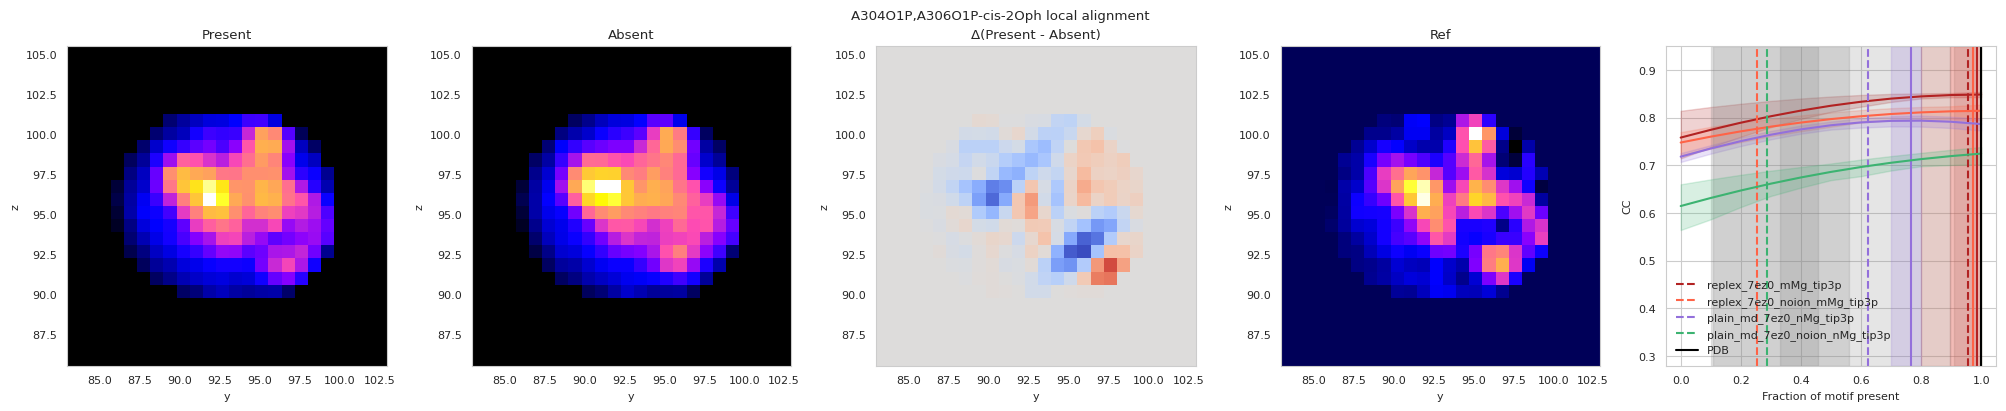

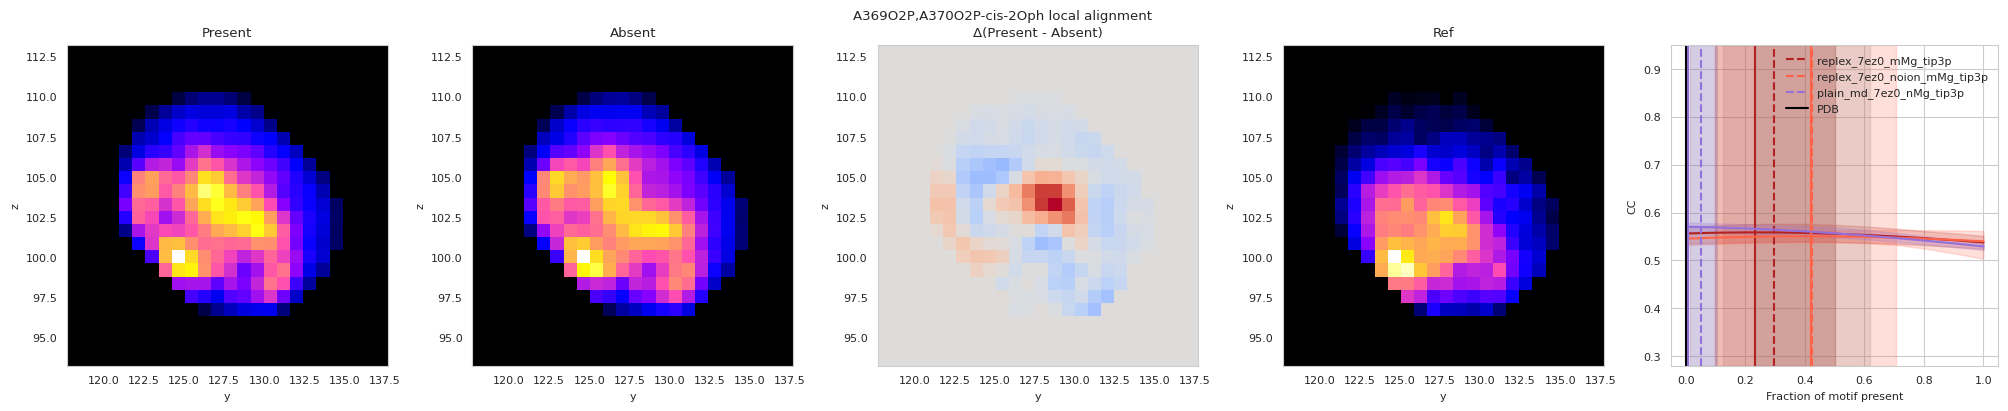

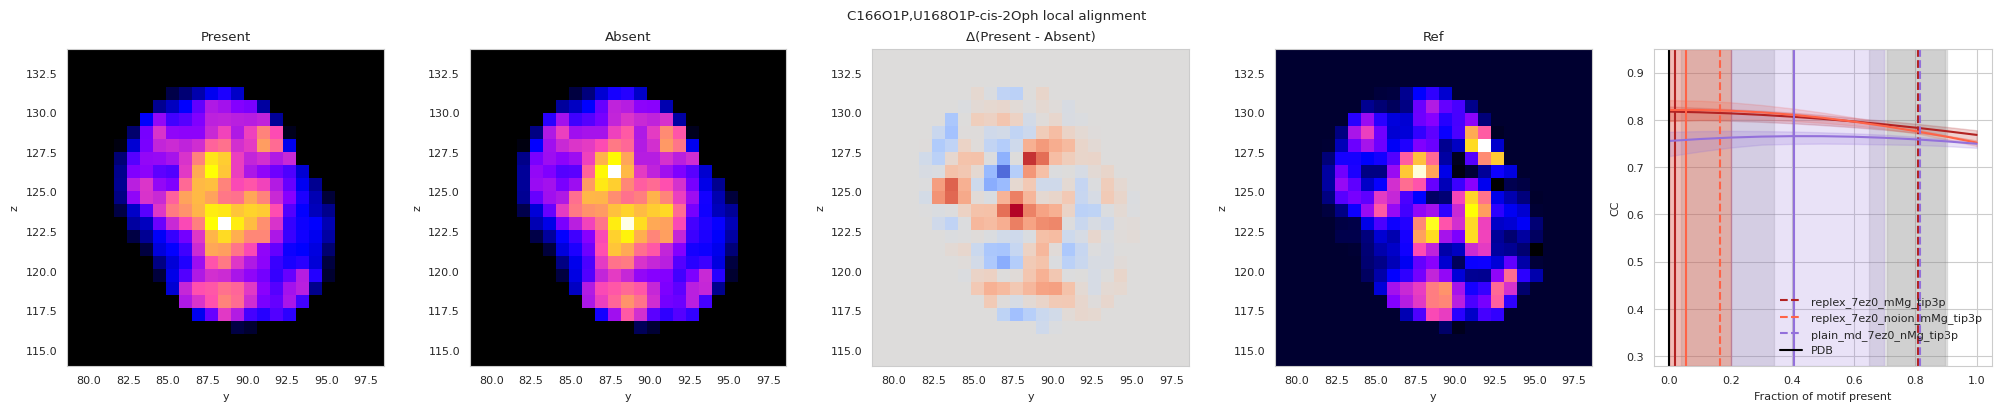

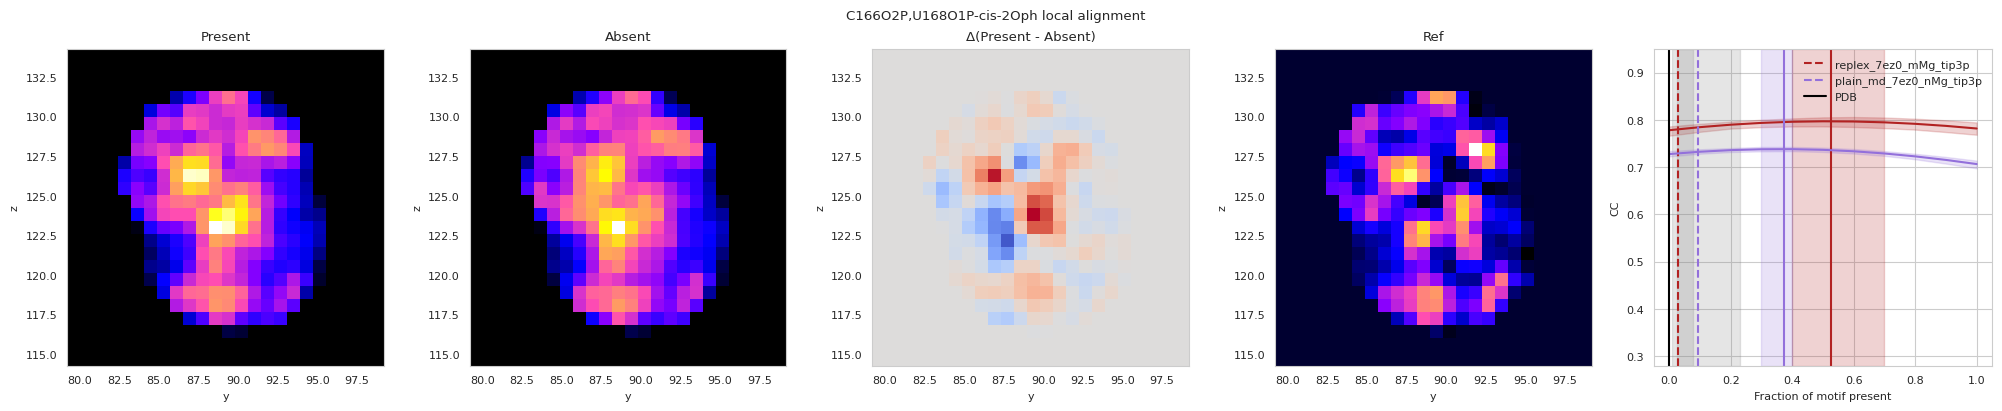

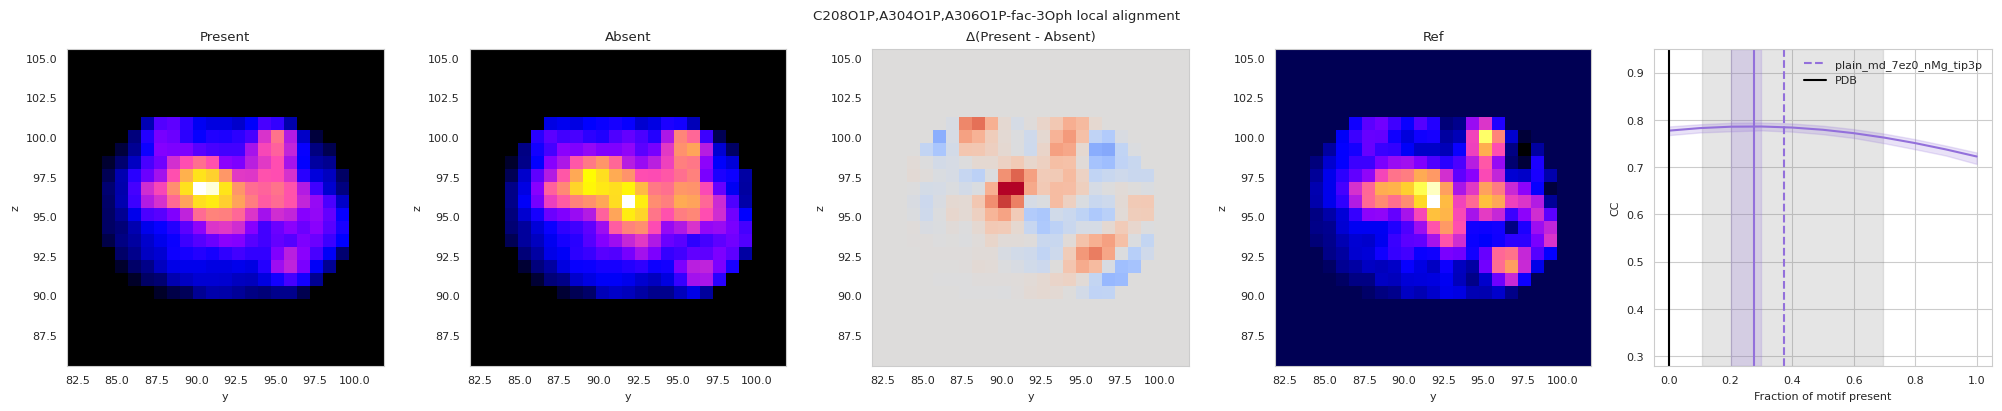

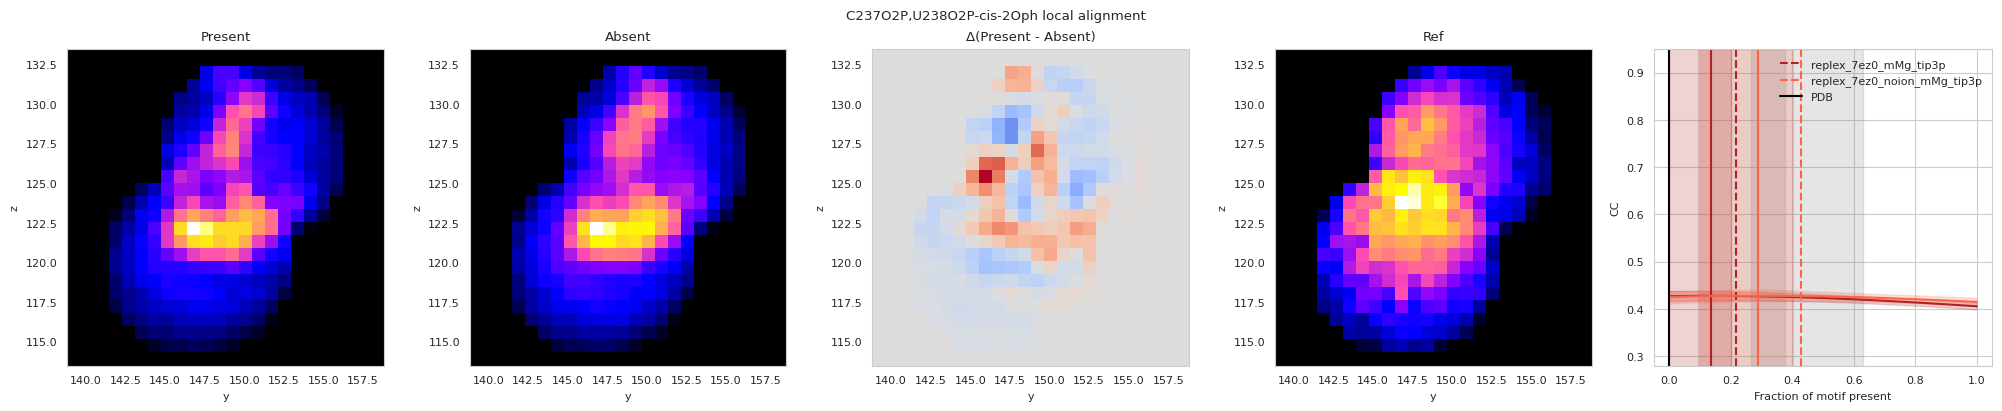

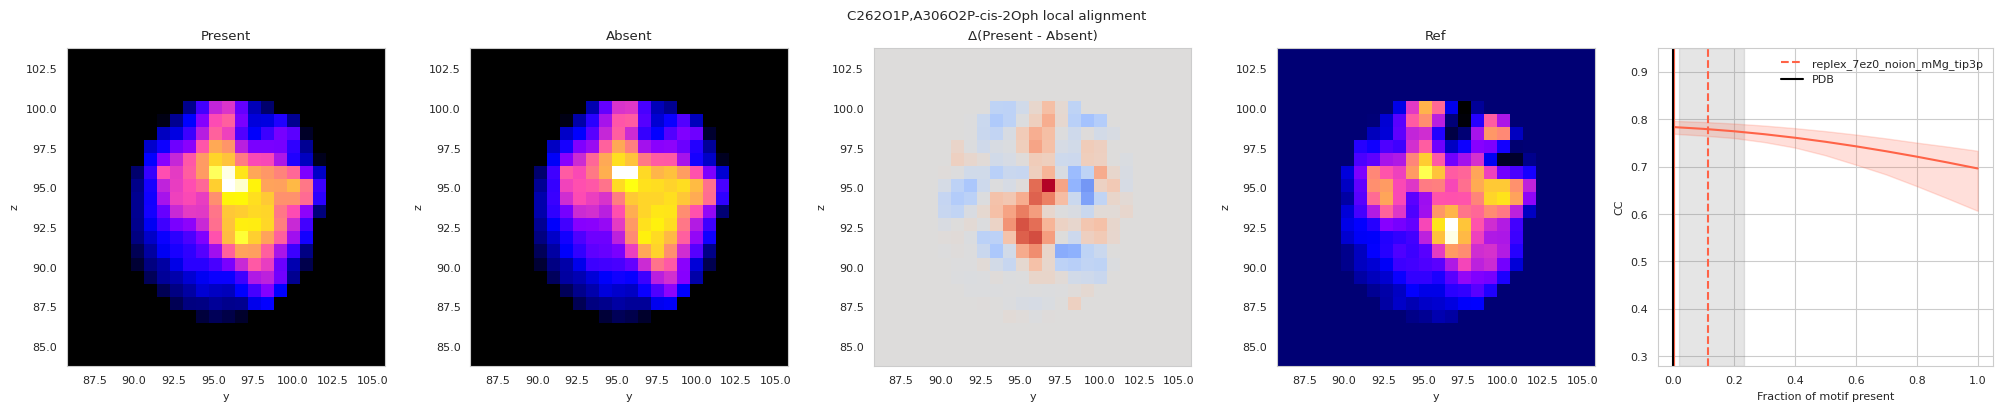

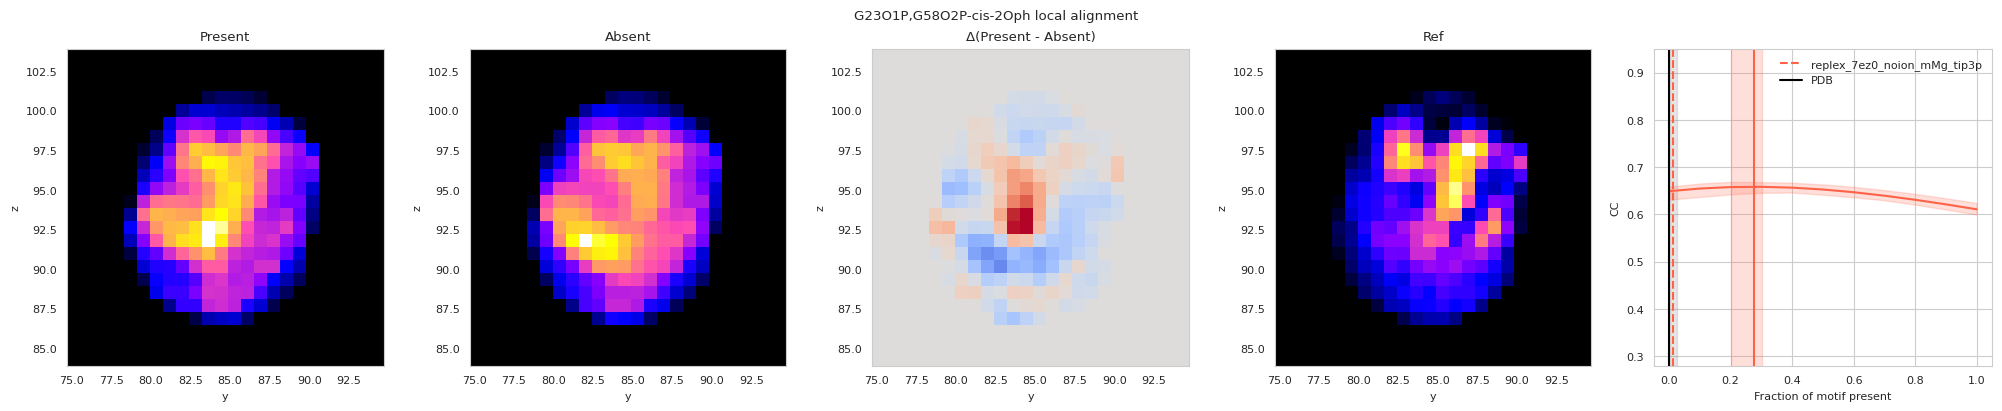

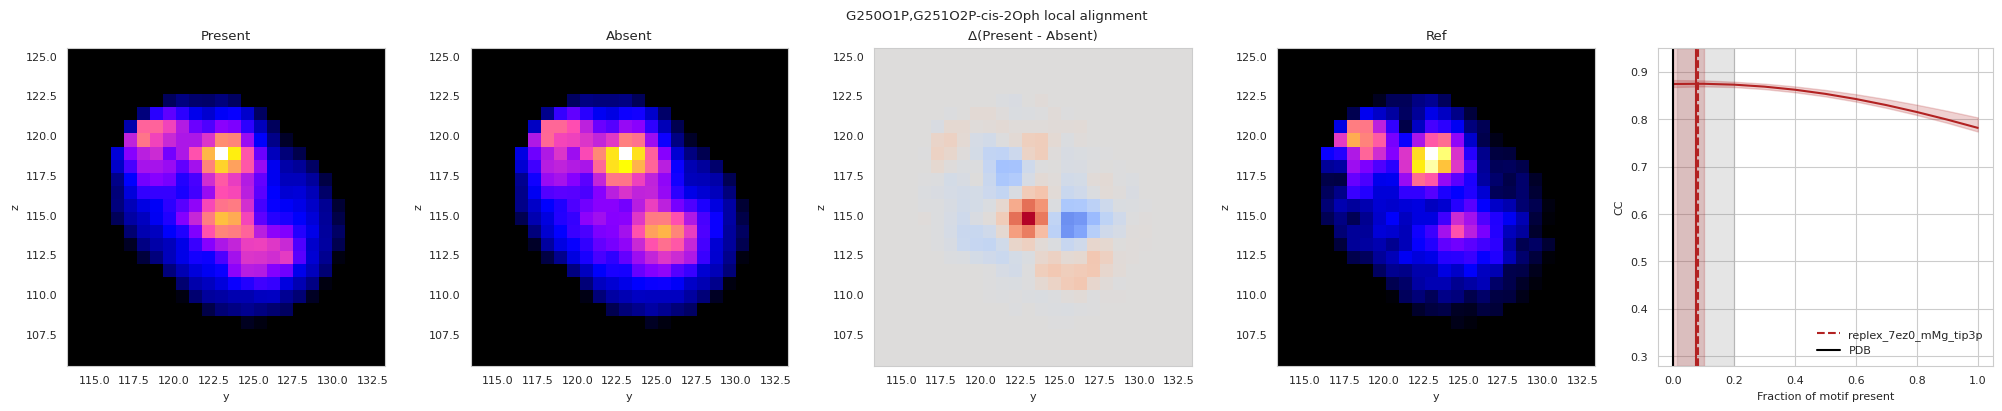

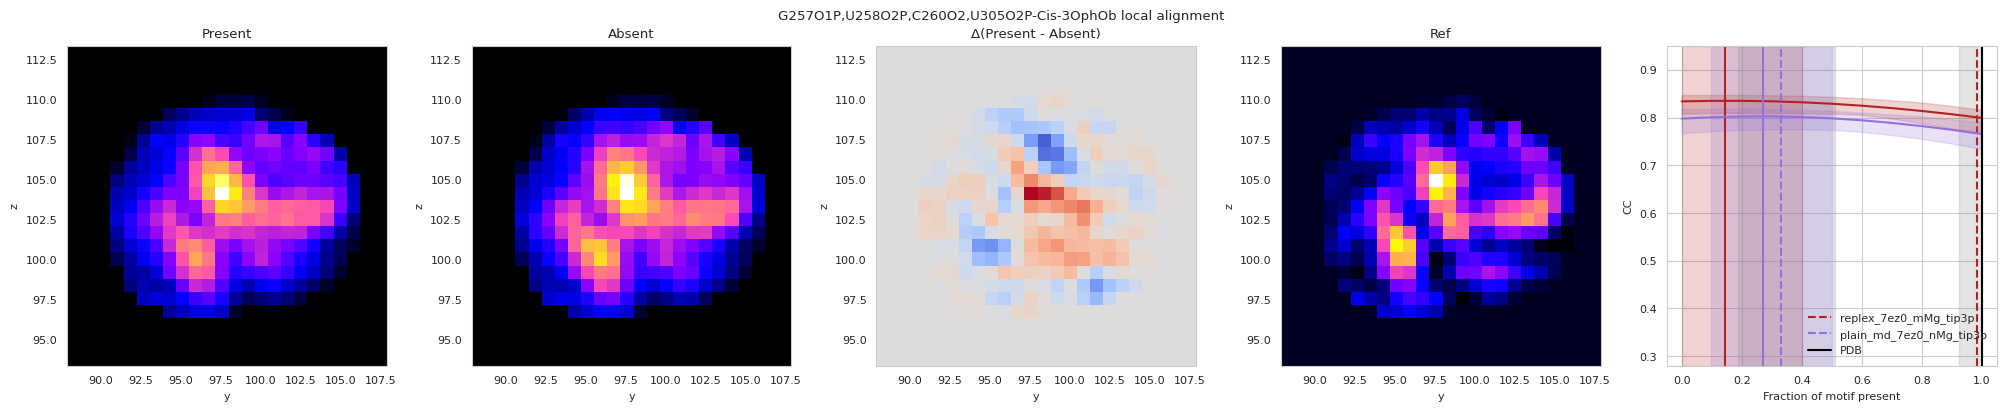

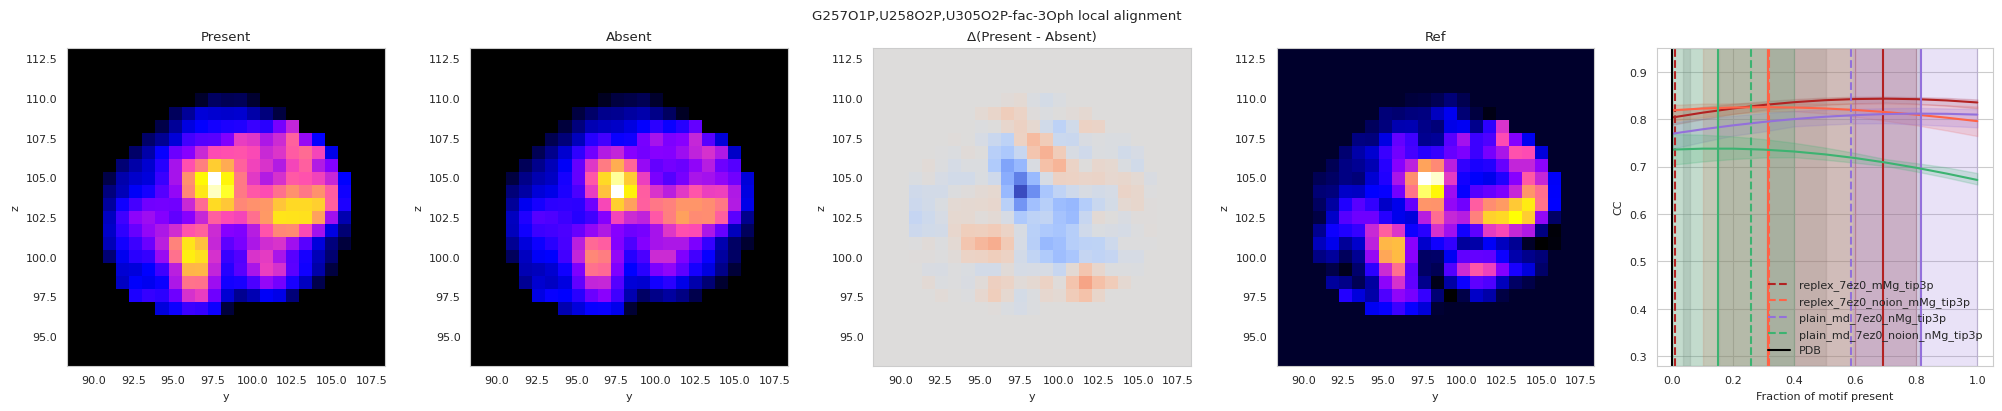

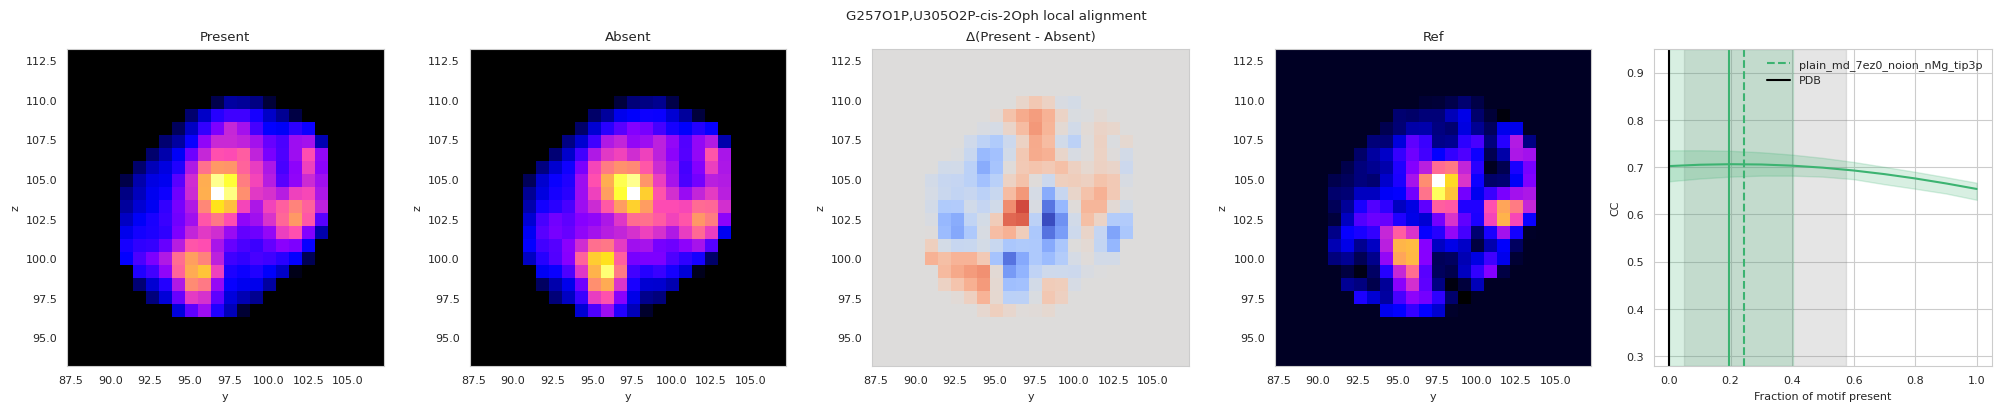

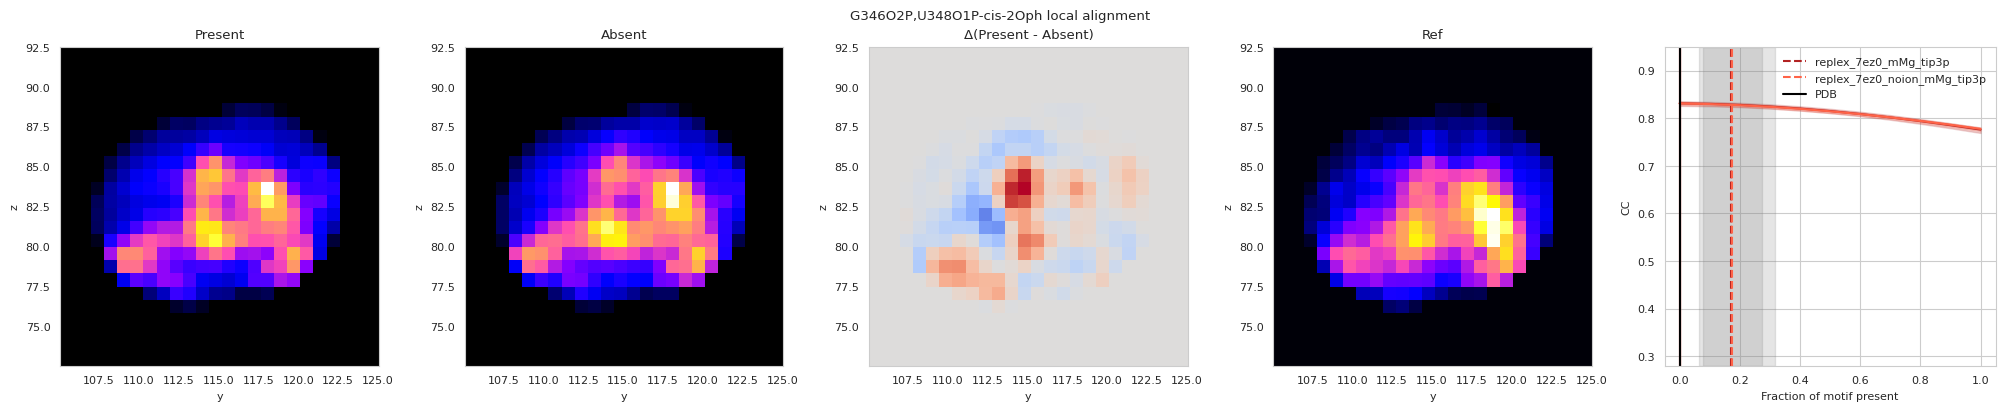

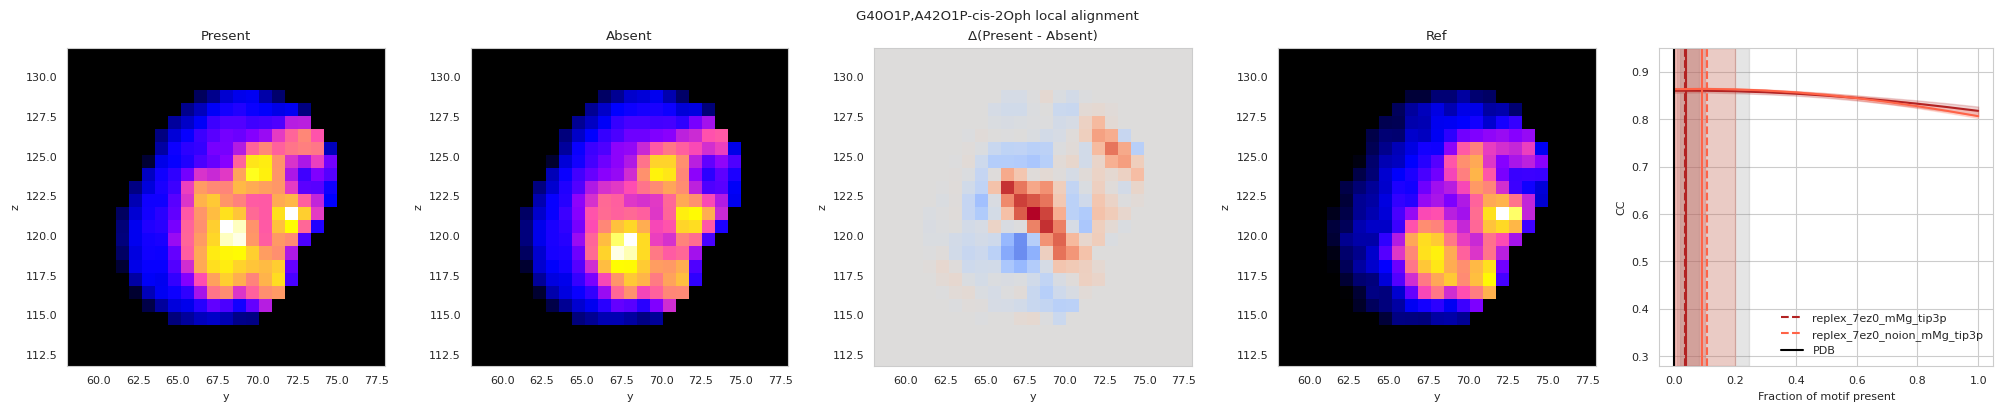

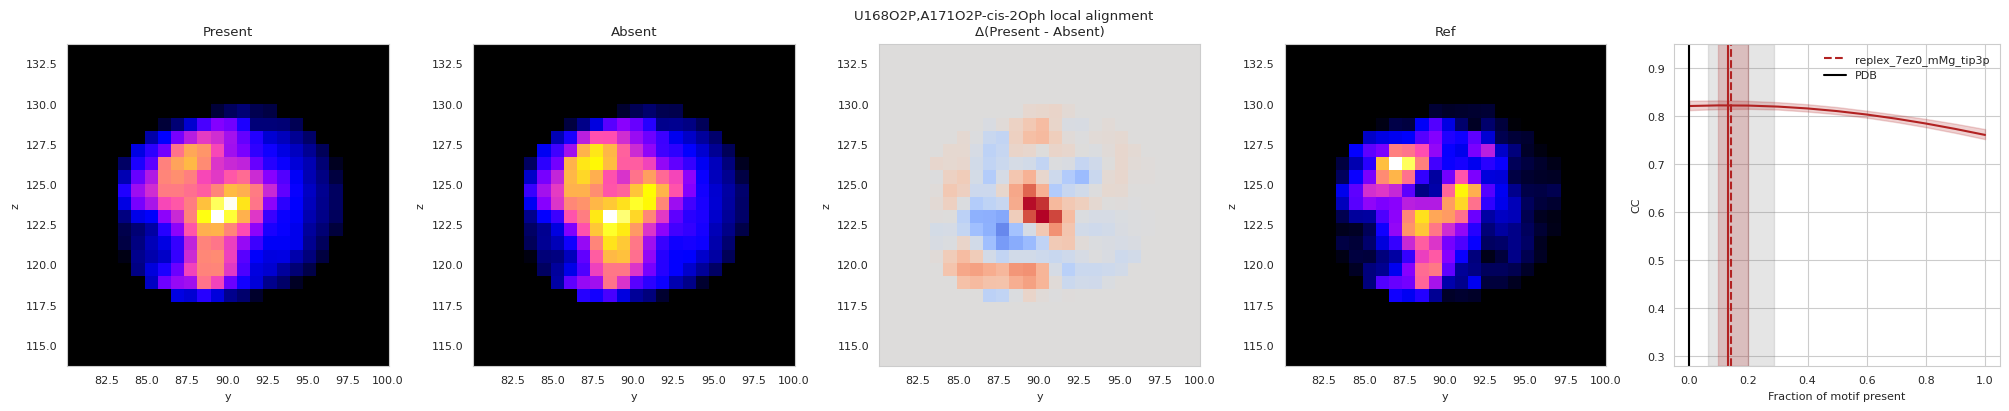

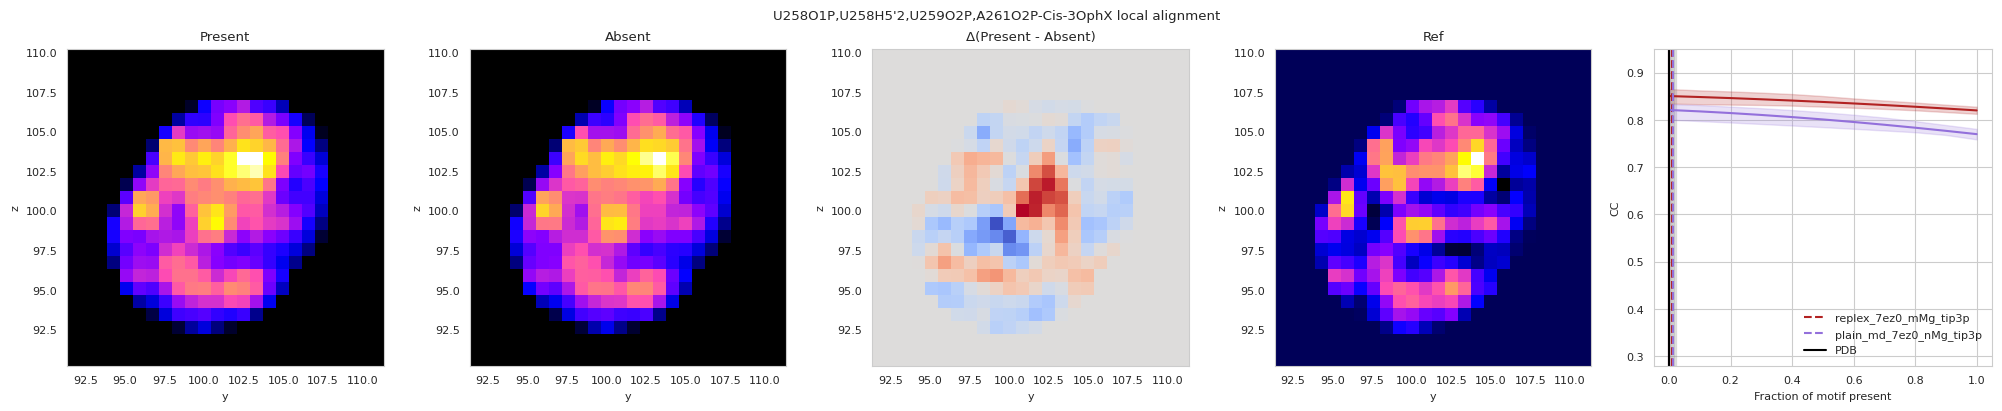

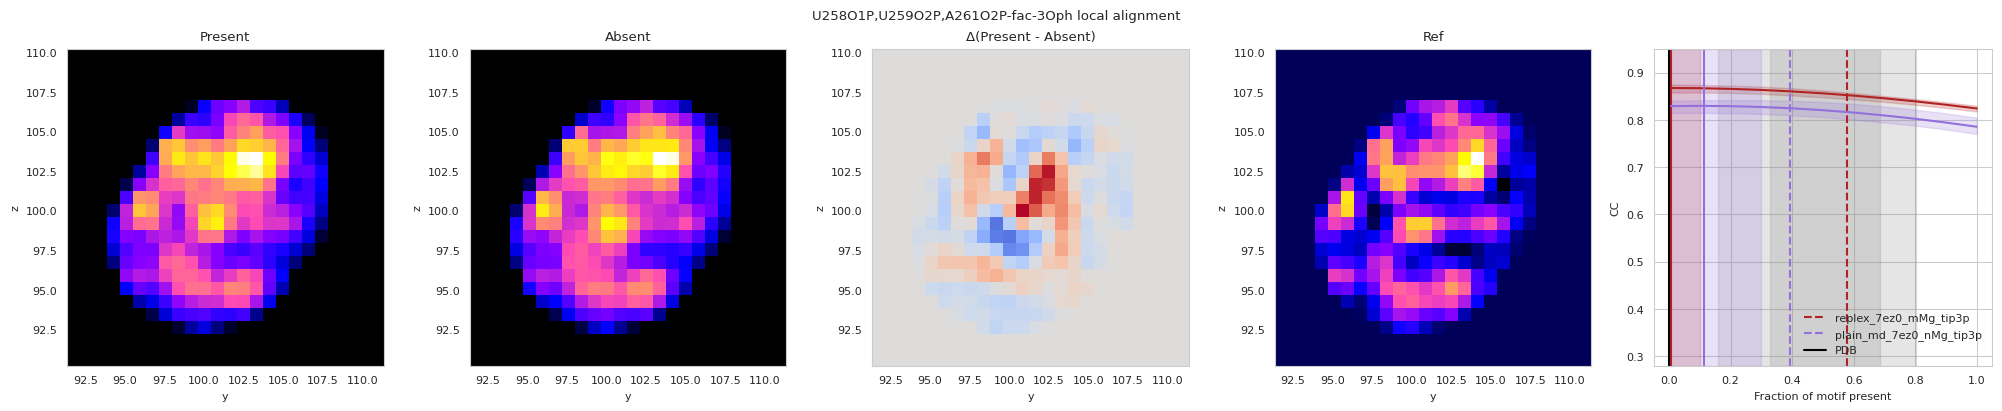

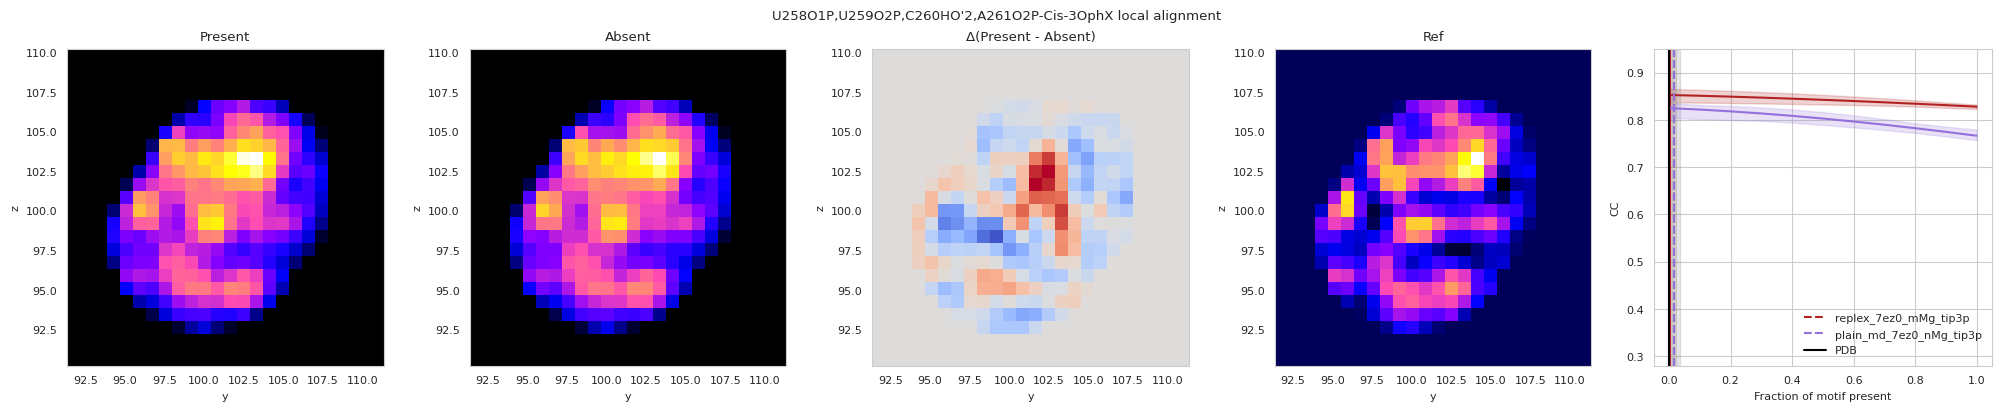

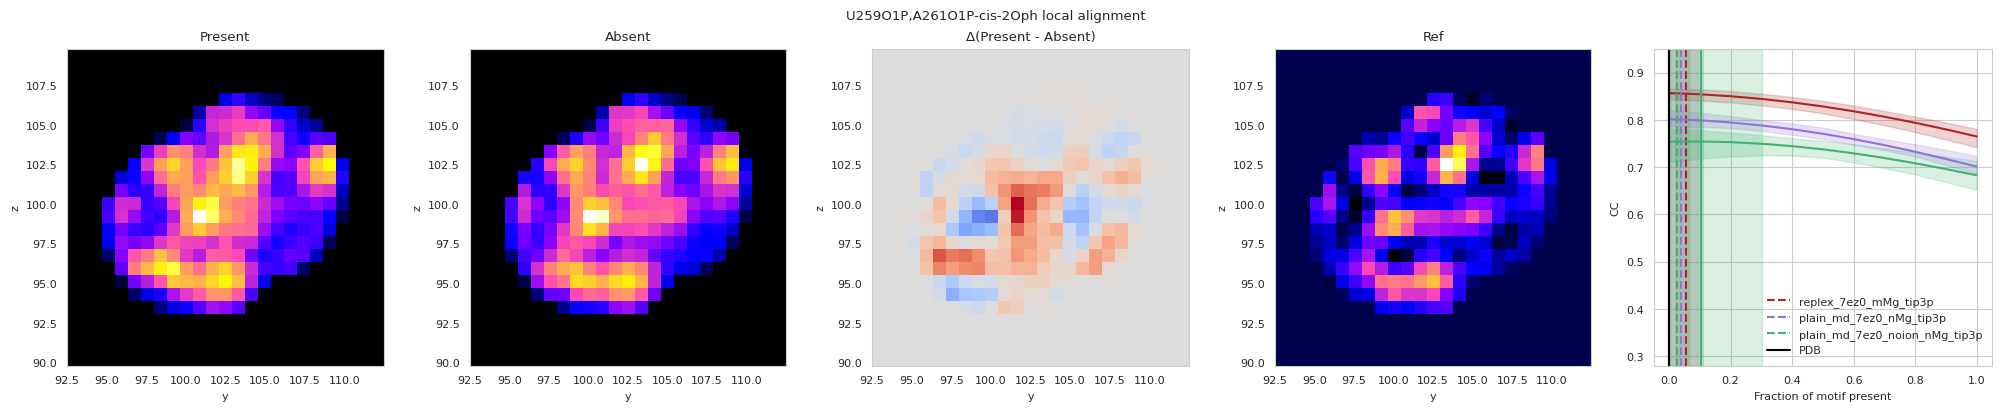

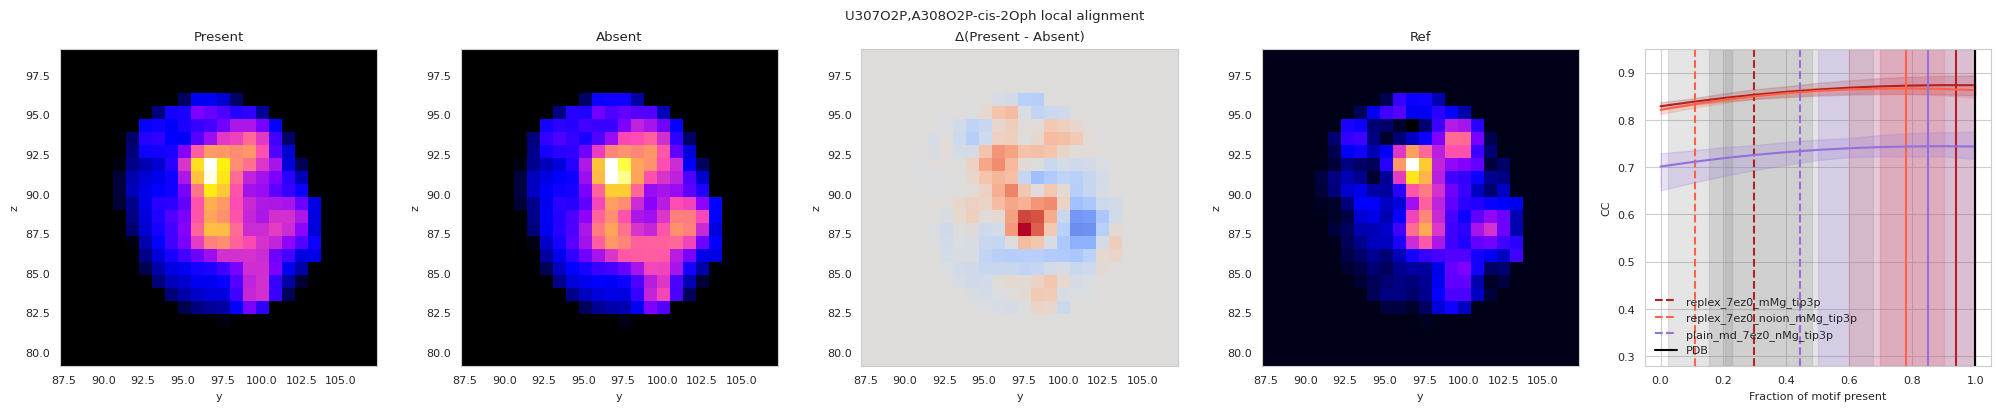

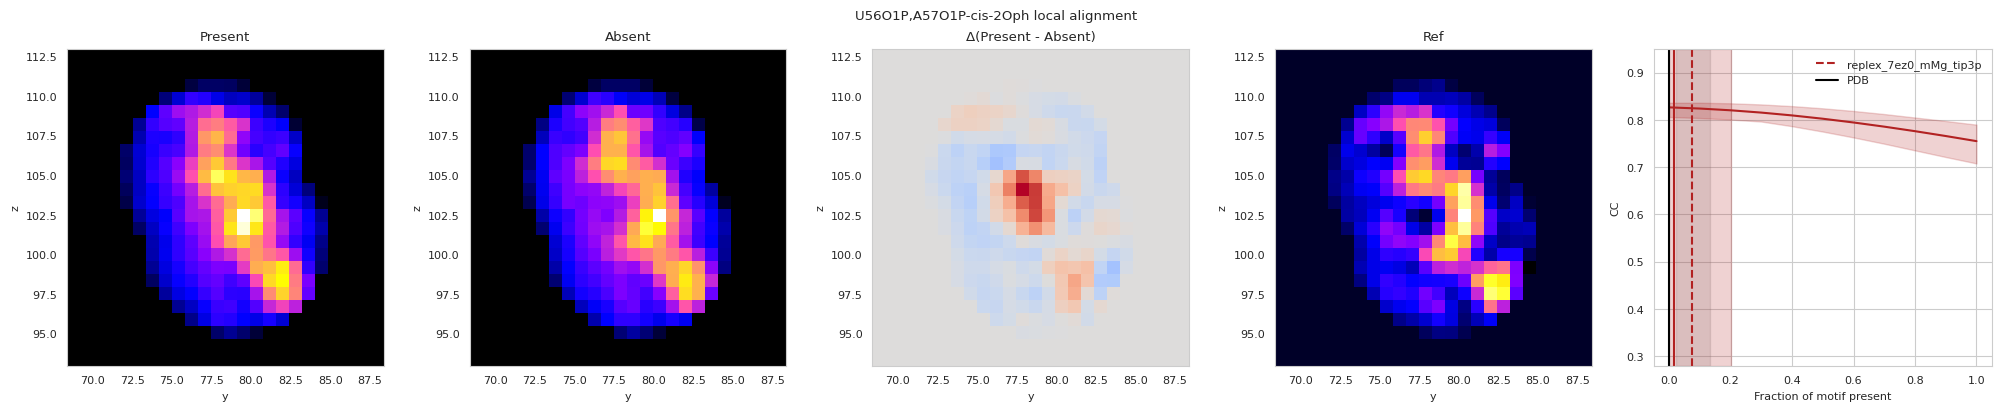

In [102]:
from matplotlib.colors import Normalize, CenteredNorm

motifs_summary = pd.concat([
    pd.read_parquet(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/MG_motifs_summary_lambda0.parquet').assign(method='replex', sys=sys, ff='mMg_tip3p')
    for sys in ('7ez0', '7ez0_noion')
])
motifs_summary = pd.concat([
    motifs_summary,
    pd.concat([
        pd.read_parquet(PROJECT_DIR / f'plain_md/{sys}/nMg_tip3p/MG_motifs_summary.parquet').assign(method='plain_md', sys=sys, ff='nMg_tip3p')
        for sys in ('7ez0', '7ez0_noion')
    ]),
])
motifs_summary = pd.concat([
    motifs_summary,
    pd.read_parquet(PROJECT_DIR / f'structures/7ez0/mMg_tip3p/MG_motifs_summary.parquet').assign(sys='7ez0_PDB')
])

for motif, group in results.groupby('motif'):
    data = motifs_summary.query('motif == @motif').iloc[0]
    inner_names, inner_resids, inner_resnames = data[['inner_names', 'inner_resids', 'inner_resnames']]
    
    ref_motif = ref.select_atoms(*[
        f"name {name} and resid {resid} and resname {resname}" 
        for name, resid, resname in zip(inner_names, inner_resids, inner_resnames)
    ])
    
    fig, axarr = plt.subplots(ncols=5, figsize=(20, 4))

    res = group.iloc[0]

    for _map, label, ax in zip((res['map_present'], res['map_absent'], res['map_present'] - res['map_absent'], res['map_ref']), ('Present', 'Absent', 'Δ(Present - Absent)', 'Ref'), axarr[:4]):

        x0, y0, z0 = ref_motif.center_of_geometry()

        cmap = 'coolwarm' if label == 'Δ(Present - Absent)' else 'gnuplot2'
        norm = CenteredNorm() if label == 'Δ(Present - Absent)' else Normalize()
        plot_map_slice(_map.to_dense(), depth=x0, plane='yz', depth_mode='coord', thickness=20, ax=ax, cmap=cmap, norm=norm)
        ax.set_xlim(y0 - 10, y0 + 10)
        ax.set_ylim(z0 - 10, z0 + 10)
        ax.set_title(label)
        ax.grid(False)
        
    ax = axarr[4]

    for _, res in group.iterrows():
        method = res['method']
        sys = res['sys']
        ff = res['ff']
        sim = f"{method}_{sys}_{ff}"
        data = motifs_summary.query('motif == @motif and method == @method and sys == @sys and ff == @ff').iloc[0]
        ax.axvline(data['p'], color=simcolors[sim], ls='dashed', label=sim)
        ax.axvspan(data['p_low'], data['p_high'], color='gray', alpha=0.2)
        line, = ax.plot(f_range, res['cc_mean'], color=simcolors[sim])
        ax.fill_between(f_range, res['cc_low'], res['cc_high'], alpha=0.2, color=line.get_color())
        ax.axvline(res['best_frac_mean'], color=line.get_color())
        ax.axvspan(res['best_frac_low'], res['best_frac_high'], color=line.get_color(), alpha=0.2)

    data = motifs_summary.query('motif == @motif and sys == "7ez0_PDB"')
    if len(data):
        ax.axvline(data.iloc[0]['p'], color='black', ls='solid', label='PDB')
    else:
        ax.axvline(0, color='black', ls='solid', label='PDB')
    
    ax.set_xlabel("Fraction of motif present")
    ax.set_ylabel("CC")
    ax.legend(frameon=False)

    ax.set_ylim(0.28, 0.95)
    fig.suptitle(f"{res['motif']} {res['alignment']} alignment")
    plt.show()

In [ ]:
fig, ax = plt.subplots()

ax.scatter(motifs_selection)

In [114]:
motifs_summary

,p,p_low,p_high,n_block_obs,n_inner,inner_indices,inner_names,inner_resids,inner_resnames,stereo,mgrna,mg_indices,method,sys,ff
motif,,,,,,,,,,,,,,,
,112.46450,1.111919e+02,113.862082,16,0,[],[],[],[],,,"[269824, 269825, 269826, 269827, 269828, 26982...",replex,7ez0,mMg_tip3p
A103O1P-Oph,0.19125,1.169821e-01,0.334182,15,1,[2606],[O1P],[103],[A],,Oph,"[269824, 269826, 269838, 269842, 269845, 12451...",replex,7ez0,mMg_tip3p
A103O2P-Oph,0.23550,1.060075e-01,0.386751,10,1,[2607],[O2P],[103],[A],,Oph,"[269856, 269826, 269798, 269832, 269833, 26983...",replex,7ez0,mMg_tip3p
A104O1P-Oph,0.10850,2.522315e-02,0.259908,3,1,[2639],[O1P],[104],[A],,Oph,"[269827, 269860, 269845]",replex,7ez0,mMg_tip3p
"A104O2P,U267O2P-cis-2Oph",0.00025,1.707429e-53,0.003022,1,2,"[2640, 7885]","[O2P, O2P]","[104, 267]","[A, U]",cis,cis-2Oph,[269879],replex,7ez0,mMg_tip3p
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"G257O1P,U258O2P,C260O2,U305O2P-Cis-3OphOb",1.00000,1.000000e+00,1.000000,8,4,"[7564, 7599, 7680, 9103]","[O1P, O2P, O2, O2P]","[257, 258, 260, 305]","[G, U, C, U]",Cis,Cis-3OphOb,[12456],NaN,7ez0_PDB,NaN
U258O1P-Oph,1.00000,1.000000e+00,1.000000,8,1,[7598],[O1P],[258],[U],,Oph,[12457],NaN,7ez0_PDB,NaN
U259O1P-Oph,1.00000,1.000000e+00,1.000000,8,1,[7628],[O1P],[259],[U],,Oph,[12458],NaN,7ez0_PDB,NaN


In [116]:
df1 = motifs_summary.reset_index().set_index(['motif', 'method', 'sys'])['p']

In [123]:
df2 = results.set_index(['motif', 'method', 'sys'])['best_frac_mean'].align(df1, join='right', axis=1)

ValueError: No axis named 1 for object type Series

In [124]:
df2

(motif                                      method  sys     
                                            replex  7ez0       NaN
 A103O1P-Oph                                replex  7ez0       NaN
 A103O2P-Oph                                replex  7ez0       NaN
 A104O1P-Oph                                replex  7ez0       NaN
 A104O2P,U267O2P-cis-2Oph                   replex  7ez0       NaN
                                                                ..
 G257O1P,U258O2P,C260O2,U305O2P-Cis-3OphOb  NaN     7ez0_PDB   NaN
 U258O1P-Oph                                NaN     7ez0_PDB   NaN
 U259O1P-Oph                                NaN     7ez0_PDB   NaN
 U305O1P-Oph                                NaN     7ez0_PDB   NaN
 U307O2P,A308O2P-cis-2Oph                   NaN     7ez0_PDB   NaN
 Name: best_frac_mean, Length: 2938, dtype: float64,
 motif                                      method  sys     
                                            replex  7ez0        112.46450
 A103O1P-Oph  